# When Does a Machine Learning Model Become Unreliable?
## An Empirical Study of Concept Drift Detection, Performance Degradation, and Model Recovery

**Notebook:** `notebooks/concept_drift_research.ipynb` &nbsp;|&nbsp; **Project:** MSc Data Science research paper

> **Important.** Every number, table and figure in this notebook is produced by executing the notebook. No result is typed in by hand. Prose that interprets results is either static background (clearly not about results) or generated by code from the executed result tables.

---
## Section 0 — Research dashboard and notebook guide

### Research objective
Investigate how changes in the data-generating process affect online (incremental) classifiers, how effectively lightweight drift detectors identify these changes, whether drift-triggered adaptation improves predictive performance relative to fixed-schedule adaptation and no adaptation, and what computational cost these strategies add.

### Research questions
* **RQ1.** How do abrupt and gradual concept drifts affect predictive performance and detection delay?
* **RQ2.** How does drift-triggered model retraining compare with fixed-window retraining and a no-retraining baseline in predictive performance and recovery time?
* **RQ3.** What trade-offs exist between predictive performance, detection delay, false alarms and computational overhead for lightweight drift detectors?

### Datasets
| Stage | Stream | Purpose |
|---|---|---|
| A | SEA-style synthetic streams (stationary, covariate-shift control, abrupt, gradual, recurring) with *known* change points | Controlled experiments with ground truth |
| B | Elec2 (electricity market) via River's dataset API | Real-world check **without** ground-truth drift points (Section 17; see the data-availability note in Section 8) |

### Experimental components
* **Model:** River `HoeffdingTreeClassifier` (primary), `GaussianNB` (small model-effect sub-experiment).
* **Detectors:** ADWIN and Page-Hinkley, each at three a-priori sensitivity levels, monitoring the binary prequential error.
* **Adaptation policies:** no adaptation; fixed-window rebuild; drift-triggered rebuild. Each rebuild is either a *reset* (fresh model) or a *replay* (fresh model trained on the last *R* already-seen labelled observations).
* **Evaluation:** prequential (test-then-train); matched alarms; recovery time; processing time and memory; paired statistics over independent seeds.

### Navigation
| # | Section | # | Section |
|---|---|---|---|
| 1 | Abstract (preliminary) | 12 | Adaptation and retraining experiments |
| 2 | Background | 13 | Controlled experiments and sensitivity |
| 3 | Literature and research gap | 14 | Statistical analysis |
| 4 | Questions and hypotheses | 15 | Comprehensive visualization |
| 5 | Environment and API validation | 16 | Results tables |
| 6 | Configuration and reproducibility | 17 | Real-world validation |
| 7 | Synthetic data generation | 18 | Discussion |
| 8 | Dataset inspection (Elec2) | 19 | Threats to validity |
| 9 | Prequential framework and tests | 20 | Conclusion and future work |
| 10 | Baseline experiment (runs the full grid) | 21 | References |
| 11 | Drift detector experiments | 22 | Final reproducibility checklist |

### How to run
```bash
python -m venv .venv && source .venv/bin/activate        # Python >= 3.10 (validated with 3.12)
pip install -r requirements.txt
jupyter lab notebooks/concept_drift_research.ipynb         # Run All (about 15-25 minutes on one CPU core)
# quick pipeline check only (never report these numbers):  DRIFT_PROFILE=smoke jupyter lab ...
```
The same experiments can run outside the notebook: `python scripts/run_experiments.py --profile full --tag main`.

### Generated outputs
`results/raw/*.csv` (run-level data), `results/logs/*` (event logs, per-observation error arrays, config snapshot, environment, validation report), `results/tables/*.csv` (all exported tables), `figures/*.png` (300 DPI) and `figures/*.pdf`, `reports/results_summary.md`, `reports/validation_report.md`.

---
## Section 1 — Abstract and research motivation

> **PRELIMINARY ABSTRACT — written before the experiments were executed. It contains no findings. The final conclusions are in Section 20.**

Machine-learning systems are usually trained on historical data and then deployed on data that keep arriving. When the process that generates the data changes — customer behaviour shifts, fraud patterns evolve, or electricity-market conditions move with demand, season and neighbouring-market transfers — a model that was accurate at training time may become unreliable without any visible failure. This study asks *when* an online classifier becomes unreliable, how quickly lightweight detectors notice, and whether reacting to an alarm is worth its cost.

We build a reproducible experimental pipeline in which an incremental Hoeffding tree is evaluated prequentially on controlled SEA-style streams whose change mechanism is explicit (change in the label rule P(Y|X), versus a pure covariate shift used as a control). Two detectors (ADWIN, Page-Hinkley) monitor the error signal; three adaptation policies (none, fixed-schedule, drift-triggered) are compared on identical data; and we measure accuracy, detection delay, false alarms, recovery time, processing time and memory over multiple independent seeds with paired statistics. A real-world electricity stream (Elec2) is used, where available, to check whether behaviour observed on synthetic streams is qualitatively similar, without assuming known drift points.

The planned contribution is a **reproducible empirical comparison under explicitly defined conditions**, not a new algorithm; the exact contribution statement is deferred until the literature and results have been reviewed (Sections 3 and 20).

**Examples of the motivation (not analysed here):** changing customer behaviour, evolving fraud tactics, and changing electricity-market dynamics. Only the last has a corresponding experiment (Elec2), and only if the dataset is reachable (see Section 8).

---
## Section 2 — Background and theoretical foundations

**Notation.** A stream is a sequence of observations $(x_t, y_t)$, $t = 0,1,2,\dots$, where $x_t \in \mathcal{X}\subseteq\mathbb{R}^d$ is a feature vector and $y_t\in\{0,1\}$ its label. At time $t$ the data are generated by a joint distribution $P_t(X,Y) = P_t(X)\,P_t(Y\mid X) = P_t(Y)\,P_t(X\mid Y)$. A model $f_t$ predicts $\hat y_t = f_t(x_t)$ and $e_t = \mathbb{1}[\hat y_t \ne y_t]$ is the error indicator.

**Batch vs online learning.** Batch learning fits a model once on a fixed training set and assumes test data follow the same distribution. Online (incremental) learning updates the model after each observation (or mini-batch) with bounded memory and time, which allows it to follow a changing distribution but also lets it *forget slowly or not at all*.

**Data streams and incremental learning.** In the stream setting data arrive in order, are processed once, and the model must be usable at any time (`predict_one`, then `learn_one`).

**Types of change.**
* **Covariate shift:** $P_t(X)$ changes while $P_t(Y\mid X)$ does not. The decision rule remains correct, although the model may be inaccurate in newly populated regions and class prevalence may shift as a side effect.
* **Prior-probability (class-prevalence) shift:** $P_t(Y)$ changes. Prevalence can change by itself or as a consequence of the other types of change.
* **Concept drift (real drift):** $P_t(Y\mid X)$ changes, so the optimal decision rule changes. A change in $P(X)$ alone is *not* concept drift under this definition, although some authors use "concept drift" for any change of the joint distribution; this notebook always states which meaning is intended and distinguishes the mechanisms explicitly.
* **Abrupt drift:** the new concept replaces the old one at a single time. **Gradual drift:** during a transition interval examples are drawn from a mixture of old and new concepts with a rising share of the new one. **Incremental drift:** the concept itself moves through intermediate states. **Recurring drift:** previous concepts reappear.

**Detection vs adaptation.** A *detector* turns a monitored signal into alarms; an *adaptation policy* decides what to do (reset, rebuild, retrain). A good detector does not guarantee a good adaptation, and vice versa.

**Prequential evaluation (test-then-train).** Each observation is first used to test the current model and only then to train it, so every observation is an out-of-sample test. Performance is tracked with a sliding window or fading factor because the cumulative average hides recent behaviour.

**Model reset vs retraining.** A *reset* discards the model and all it has learned; the new model learns only from observations that arrive afterwards (plus, here, the current one). *Retraining on a window* rebuilds a model from a buffer of recent labelled observations; this requires storing those observations (memory) and recomputing the model (time). Neither is the same as batch retraining on all history.

**False alarms and detection delay.** A *false alarm* is an alarm when no relevant change occurred; *detection delay* is the number of observations between the true change and the first valid alarm. Reducing delay generally requires lowering the evidence needed to raise an alarm, which also raises the false-alarm rate.

**Detector principles.** ADWIN maintains an adaptive window and signals when two sub-windows have significantly different means (confidence parameter $\delta$). Page-Hinkley accumulates $m_T=\sum_{t\le T}(x_t-\bar x_t-\delta)$ and signals when $m_T-\min_{t\le T} m_t>\lambda$ (tolerance $\delta$, threshold $\lambda$); the $\delta$ and $\lambda$ of Page-Hinkley are not comparable to ADWIN's $\delta$.

---
## Section 3 — Literature review and research gap

All sources below were checked against at least one publisher, repository or index record **during this project** (title, authors, year, venue, DOI/URL). Details of a paper that were not visible in the checked records are marked *not verified* rather than filled in from memory.

| ID | Full title | Authors | Year | Venue | DOI / URL | Main method | Evaluation setting | Relevant finding | Limitation for this project |
|---|---|---|---|---|---|---|---|---|---|
| [1] | A survey on concept drift adaptation | J. Gama, I. Žliobaitė, A. Bifet, M. Pechenizkiy, A. Bouchachia | 2014 | ACM Computing Surveys 46(4), Art. 44 | 10.1145/2523813 | Survey: characterises adaptive learning, categorises strategies, discusses evaluation methodology | Survey (no single dataset) | Defines concept drift as a change in the relation between inputs and target; frames detection and adaptation as separate concerns | Predates later detectors; no new experiments |
| [2] | Learning under concept drift: a review | J. Lu, A. Liu, F. Dong, F. Gu, J. Gama, G. Zhang | 2019 | IEEE TKDE 31(12):2346–2363 | 10.1109/TKDE.2018.2876857 | Review of >130 publications; framework of drift detection, understanding, adaptation | Lists 10 synthetic and 14 real benchmark datasets | Organises the field into detection, understanding and adaptation | Review only; no controlled comparison of our policies |
| [3] | Learning from time-changing data with adaptive windowing | A. Bifet, R. Gavaldà | 2007 | Proc. SIAM Int. Conf. Data Mining, pp. 443–448 | 10.1137/1.9781611972771.42 | ADWIN: sliding window whose size is recomputed from observed change; rigorous bounds on false-positive and false-negative rates; used to monitor Naïve Bayes error or inside NB | Synthetic and real streams | Source of the ADWIN detector used here | Guarantees are about the window-mean test under its assumptions, not about downstream accuracy; library parameter defaults are implementation choices |
| [4] | Continuous inspection schemes | E. S. Page | 1954 | Biometrika 41(1–2):100–115 | 10.1093/biomet/41.1-2.100 | CUSUM scheme for sequential change detection; average run length as performance measure | Quality-control sampling | Origin of the cumulative-sum idea behind Page-Hinkley | Not a machine-learning paper; assumptions are parametric |
| [5] | Inference about the change-point from cumulative sum tests | D. V. Hinkley | 1971 | Biometrika 58(3):509–523 | 10.1093/biomet/58.3.509 | Change-point inference from CUSUM tests; commonly known as the Page-Hinkley test | Sequence of normal random variables (per abstract) | Theory behind the PH test used here | Derived for normal observations; our signal is a Bernoulli error indicator |
| [6] | On evaluating stream learning algorithms | J. Gama, R. Sebastião, P. P. Rodrigues | 2013 | Machine Learning 90(3):317–346 | 10.1007/s10994-012-5320-9 | Prequential error with forgetting (sliding window, fading factors) as estimator; change-detection experiments | Drift scenarios | Justifies windowed prequential evaluation | Does not compare adaptation policies |
| [7] | A comparative study on concept drift detectors | P. M. Gonçalves Jr., S. G. T. de Carvalho Santos, R. S. M. Barros, D. C. L. Vieira | 2014 | Expert Systems with Applications (online 19 Jul 2014) | 10.1016/j.eswa.2014.07.019 | Eight detectors; 2^k factorial design to choose parameters; accuracy, time, false-alarm and miss rates | Several datasets (per record highlights) | Closest in metrics (false alarms, misses, time); reports DDM best on average in that study | Different detector set; volume/pages not verified here |
| [8] | A large-scale comparison of concept drift detectors | R. S. M. Barros, S. G. T. Santos | 2018 | Information Sciences 451–452:348–370 | 10.1016/j.ins.2018.04.014 | Large-scale detector comparison (per title) | *Not verified* (abstract not read) | Shows that systematic detector benchmarking is an established topic | Content beyond the title not verified in this project |
| [9] | A streaming ensemble algorithm (SEA) for large-scale classification | W. N. Street, Y. Kim | 2001 | Proc. 7th ACM SIGKDD (KDD '01), pp. 377–382 | 10.1145/502512.502568 | Ensemble on sequential chunks; source of the SEA concept stream | Large-scale/streaming data | Origin of SEA-style generators (3 attributes in [0,10], 2 relevant, sum-threshold rule) | Original SEA drift = threshold change; our swap concept is an extension |
| [10] | Mining high-speed data streams | P. Domingos, G. Hulten | 2000 | Proc. 6th ACM SIGKDD (KDD '00), starting p. 71 | 10.1145/347090.347107 | Hoeffding-tree learning from streams | *Not verified beyond citation record* | Source of the Hoeffding-tree family used as base learner | Details not re-checked here |
| [11] | River: machine learning for streaming data in Python | J. Montiel et al. | 2021 | JMLR 22(110):1–8 | https://jmlr.org/papers/v22/20-1380.html | Library for stream learning with generators, learners, drift detectors, evaluators | – | Software used for models, detectors and dataset access | Library defaults can differ across versions |

### What the checked literature covers
Surveys [1], [2] organise the field and stress that detection and adaptation are different tasks; [3], [4], [5] define the two detectors used; [6] supports windowed prequential evaluation; [7], [8] show that benchmarking detectors on false alarms, misses and cost is an established activity; [9], [10], [11] supply the generator, base learner and software.

### Research gap (stated conservatively)
This search was **not** an exhaustive systematic review, so no claim of novelty is made. Within the verified sources, the study aims to provide, in one reproducible, laptop-scale protocol with open code:
1. a **factorial separation** of detector (ADWIN, Page-Hinkley), detector sensitivity (3 a-priori levels), adaptation *trigger* (none / fixed / drift) and adaptation *action* (reset / replay) on **identical streams** with paired seeds;
2. scenarios that **separate** a change of $P(Y\mid X)$ (with and without class-prevalence change) from a pure covariate-shift control;
3. an explicit, pre-registered **alarm-matching rule and recovery definition**, plus processing time and memory;
4. paired statistics over independent seeds with Holm correction.

### Literature-verification checklist (NOT verified — not cited, not in the bibliography)
Candidate sources that should be verified before citing in the final paper: Demšar (2006) on statistical comparison of classifiers; Webb et al. (2016) on characterising concept drift; Bayram, Ahmed & Kassler (2022) on performance-aware drift detectors; Hoens, Polikar & Chawla (2012) on drift and imbalance; Gama et al. (2004) on DDM; Baena-García et al. (2006) on EDDM; Harries (1999, SPLICE-2 electricity report) for the original Elec2 description. The first-listed items are suggestions from memory of the field, **not** confirmed records.

---
## Section 4 — Research questions and hypotheses

A **research question** asks what we want to understand; a **statistical hypothesis** is a testable statement about a population parameter. RQ1–RQ3 are answered in Section 18 using the evidence of Sections 10–14; H1–H3 are tested statistically.

| Hyp. | Statement (to be tested, not assumed) | Independent variables | Dependent variables | Experimental comparison | Evaluation metric | Expected direction (if justified) | Conditions under which it might fail |
|---|---|---|---|---|---|---|---|
| **H1** | Performance degrades after a meaningful change in the data-generating process | Scenario (concept-drift scenarios vs control streams) | Accuracy in drift window vs pre-drift window | Paired per-seed difference for the *no-adaptation* policy; the stationary stream (same seed, same windows) is the control, giving a difference-in-differences | Mean paired accuracy drop and excess drop vs control, bootstrap CI, Wilcoxon (Holm) | Drop for concept drift; no drop for stationary control; covariate shift uncertain | New concept overlaps the old (small disagreement); learner adapts by itself; window too short/long |
| **H2** | Drift-triggered adaptation can improve post-drift performance over never adapting; improvement depends on drift type and detector | Policy (none, fixed, ADWIN-/PH-triggered; reset or replay), drift type | Drift-window accuracy, recovery time, overall accuracy | Paired per-seed difference to *no adaptation* | Mean difference, CI, Cohen's $d_z$, Wilcoxon (Holm) | Positive for abrupt drift if the detector fires; weaker for gradual drift | Late/missed detection; false-alarm resets harm the model; reset loses information; gradual drift handled by incremental learning |
| **H3** | More sensitive detection reduces delay but increases false alarms and overhead | Detector, sensitivity level | Detection delay, false alarms per 1000, alarms/adaptations, µs per observation | Sensitive vs conservative (and default), paired per seed | Same as above | Delay ↓, false alarms ↑, adaptations ↑ with sensitivity | Parameters of ADWIN and PH are not equivalent; small number of alarms; ceiling effects |

---
## Section 5 — Environment setup and dependency validation

**What the code does.** Records interpreter and library versions, verifies that every required import works, and runs a lightweight compatibility check of each API the study relies on (stream generation, `predict_one`/`learn_one`, detector `update`/`drift_detected`, alarm direction semantics, metric calculation).
**Why.** Method names and defaults differ across River versions; the study must use the *installed, documented* API rather than assumed names.
**Output.** A version table, a pass/fail compatibility table, and `results/logs/environment.txt`.

Dependencies are pinned in `requirements.txt`. If a package is missing, run `pip install -r requirements.txt` once in a terminal (the notebook does not reinstall anything automatically).

In [1]:
import os, sys, json, time, platform, warnings, inspect, subprocess, importlib
from pathlib import Path

# Robust project-root detection: independent of the notebook's working directory.
_here = Path.cwd().resolve()
ROOT = next(p for p in [_here, *_here.parents] if (p / "pyproject.toml").exists() and (p / "src").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40); pd.set_option("display.precision", 4)
matplotlib.rcParams["figure.dpi"] = 100          # inline size; files are saved at 300 DPI

def observed(text: str) -> None:
    # Display result-derived text produced by code (never typed in advance).
    display(Markdown("**Observed pattern (auto-generated from the executed results):** " + text))

print("project root:", ROOT)

project root: /home/claude/concept-drift-research


In [2]:
import importlib.metadata as md
required = ["river", "numpy", "pandas", "scipy", "scikit-learn", "matplotlib", "seaborn", "statsmodels", "PyYAML",
            "ipython", "pytest", "nbformat", "psutil"]
rows = []
for p in required:
    try:
        rows.append({"package": p, "version": md.version(p), "import_ok": True})
    except md.PackageNotFoundError:
        rows.append({"package": p, "version": "MISSING", "import_ok": False})
env = pd.DataFrame(rows)
display(env)
assert env["import_ok"].all(), "Missing packages: run `pip install -r requirements.txt` in a terminal."
PYTHON_VERSION = platform.python_version()
print("Python", PYTHON_VERSION, "|", platform.platform(), "| CPU cores:", os.cpu_count())
(ROOT / "results" / "logs").mkdir(parents=True, exist_ok=True)
(ROOT / "results" / "logs" / "environment.txt").write_text(
    f"python {PYTHON_VERSION}\nplatform {platform.platform()}\n" + "\n".join(f"{r.package}=={r.version}" for r in env.itertuples()))

,package,version,import_ok
0,river,0.26.1,True
1,numpy,2.4.4,True
2,pandas,3.0.2,True
3,scipy,1.17.1,True
4,scikit-learn,1.8.0,True
5,matplotlib,3.10.8,True
6,seaborn,0.13.2,True
7,statsmodels,0.15.0,True
8,PyYAML,6.0.3,True
9,ipython,9.17.1,True


Python 3.12.3 | Linux-6.18.44-fc-v185-x86_64-with-glibc2.39 | CPU cores: 1


271

In [3]:
import src
from src.config import load_config, make_variants, find_project_root
from src.data_streams import *
from src.models import make_model_factory, check_online_api
from src.detectors import *
from src.evaluation import *
from src.experiments import *
from src.reporting import *
from src.statistical_analysis import *
from src import visualization as viz

from river import drift, tree, datasets, naive_bayes

# ---- lightweight compatibility checks of every API used in the study ----
checks = []
def check(name, fn):
    try:
        ok, detail = fn()
    except Exception as exc:
        ok, detail = False, f"{type(exc).__name__}: {exc}"
    checks.append({"check": name, "passed": bool(ok), "detail": detail})

def _gen():
    cfg_ = load_config("smoke", root=ROOT)
    sd = generate_stream(make_scenario_specs(cfg_.stream)["abrupt_swap"], cfg_.stream, 1)
    return len(sd) == cfg_.stream.length, f"X{sd.X.shape}, y mean={sd.y.mean():.2f}"
def _river_sea():
    rows = list(datasets.synth.SEA(variant=0, seed=1).take(5)); return len(rows) == 5, f"keys={list(rows[0][0])}"
def _model():
    m = tree.HoeffdingTreeClassifier(); check_online_api(m)
    first = m.predict_one({"x1": 1.0, "x2": 2.0, "x3": 3.0}); m.learn_one({"x1": 1.0, "x2": 2.0, "x3": 3.0}, 1)
    return True, f"untrained predict_one -> {first!r} (recorded as class 0); learn_one OK"
def _adwin():
    a = drift.ADWIN(); rng = np.random.default_rng(0)
    s = np.r_[rng.random(2000) < .1, rng.random(2000) < .4].astype(float); up = dn = 0
    for v in s:
        before = a.estimation; a.update(v)
        if a.drift_detected: up += a.estimation > before; dn += a.estimation <= before
    return a.drift_detected in (True, False), f"alarms with error increase={up}, decrease={dn} (attribute drift_detected exists)"
def _adwin_dir():
    s = np.r_[np.random.default_rng(1).random(3000) < .4, np.random.default_rng(2).random(3000) < .1].astype(float)
    raw = ADWINDetector(direction="both"); flt = ADWINDetector(direction="increase")
    for v in s: raw.update(v); flt.update(v)
    return raw.n_raw_alarms >= 1 and flt.n_accepted < raw.n_accepted + 1, \
        f"on an error DECREASE: raw ADWIN alarms={raw.n_raw_alarms}; accepted by 'increase' filter={flt.n_accepted}"
def _ph():
    out = {}
    for mode in ("up", "down", "both"):
        d = drift.PageHinkley(mode=mode); s = np.r_[np.random.default_rng(0).random(3000) < .1, np.random.default_rng(3).random(3000) < .4].astype(float)
        out[mode] = sum(1 for v in s if (d.update(v) or d.drift_detected))
    return out["up"] >= 1 and out["down"] == 0, f"alarms on an error INCREASE by mode: {out}"
def _ph_reset():
    d = drift.PageHinkley(mode="up"); s = np.r_[np.zeros(500), np.ones(1500)]
    n = sum(1 for v in s if (d.update(v) or d.drift_detected)); return n == 1, f"alarms on a single 0->1 step: {n} (detector resets itself after an alarm)"
def _metrics():
    yt, yp = np.array([1, 0, 1, 1]), np.array([1, 0, 0, 1]); m = precision_recall_f1(yt, yp)
    return abs(m["recall"] - 2 / 3) < 1e-9 and window_accuracy((yt != yp).astype(float), 0, 4) == 0.75, f"precision={m['precision']:.2f} recall={m['recall']:.2f}"
def _spec():
    s = detector_specs(load_config("smoke", root=ROOT).detector); return len(s) == 6, f"{sorted(s)}"
for n, f in [("synthetic generator (src.data_streams)", _gen), ("River SEA generator", _river_sea),
             ("Hoeffding tree predict_one/learn_one", _model), ("ADWIN update/drift_detected/estimation", _adwin),
             ("ADWIN direction semantics (decrease is NOT degradation)", _adwin_dir),
             ("Page-Hinkley modes (up detects increases only)", _ph), ("Page-Hinkley self-reset after alarm", _ph_reset),
             ("metric calculations", _metrics), ("detector specifications", _spec)]:
    check(n, f)
compat = pd.DataFrame(checks); display(compat)
assert compat["passed"].all(), "API compatibility problem: see table above"

,check,passed,detail
0,synthetic generator (src.data_streams),True,"X(3000, 3), y mean=0.66"
1,River SEA generator,True,"keys=[0, 1, 2]"
2,Hoeffding tree predict_one/learn_one,True,untrained predict_one -> None (recorded as cla...
3,ADWIN update/drift_detected/estimation,True,"alarms with error increase=1, decrease=0 (attr..."
4,ADWIN direction semantics (decrease is NOT deg...,True,on an error DECREASE: raw ADWIN alarms=1; acce...
5,Page-Hinkley modes (up detects increases only),True,"alarms on an error INCREASE by mode: {'up': 1,..."
6,Page-Hinkley self-reset after alarm,True,alarms on a single 0->1 step: 1 (detector rese...
7,metric calculations,True,precision=1.00 recall=0.67
8,detector specifications,True,"['adwin_conservative', 'adwin_default', 'adwin..."


**Reading the table.** ADWIN raises an alarm for a significant change of the window mean in *either* direction, so on an error stream a *decrease* (the model improving) also triggers it. The study therefore uses a documented direction filter (`ADWINDetector(direction="increase")`): an alarm is accepted only if the window mean after the cut is larger than before it. Rejected alarms are still counted (`n_raw_alarms`) so the effect of the filter is visible. Page-Hinkley is run in `mode="up"`, which only detects increases of the mean.

---
## Section 6 — Configuration and reproducibility

**What the code does.** Loads `configs/default.yaml` into typed dataclasses (`src/config.py`). Every experimental constant — seeds, stream length, drift positions, transition widths, model and detector parameters, fixed-window size, evaluation windows, repetitions, output directories — is a named configuration value. `make_variants` creates configuration variants (used here only to demonstrate the helper; sensitivity analyses are run through the same mechanism).
**Seeds.** The stream seed is `base_seed + i`. All scenarios with the same seed share the same random draws (common random numbers), so differences between scenarios and between policies are not confounded by sampling noise. Models and detectors are deterministic given the data.
**Profiles.** `full` (the study) and `smoke` (a quick pipeline check; never reported as a result). Select via the environment variable `DRIFT_PROFILE` before starting Jupyter.

In [4]:
PROFILE = os.environ.get("DRIFT_PROFILE", "full")
TAG = "main" if PROFILE == "full" else PROFILE
cfg = load_config(PROFILE, root=ROOT)
print(f"PROFILE={PROFILE!r}  seeds={cfg.run.n_seeds}  stream length={cfg.stream.length}  base seed={cfg.run.base_seed}")
if PROFILE != "full":
    display(Markdown("> **WARNING: smoke profile — numbers produced in this run are only a pipeline check and must not be reported.**"))
print(json.dumps({k: v for k, v in cfg.to_dict().items() if k != "paths"}, indent=1, default=str)[:3500])

variants = make_variants(cfg, {"adaptation.fixed_window": [cfg.adaptation.fixed_window // 2, cfg.adaptation.fixed_window],
                               "stream.label_noise": [0.0, cfg.stream.label_noise]})
print("\nconfiguration variants generated by make_variants:", [(v.adaptation.fixed_window, v.stream.label_noise) for v in variants])

PROFILE='full'  seeds=20  stream length=10000  base seed=20260101
{
 "stream": {
  "length": 10000,
  "n_features": 3,
  "feature_low": 0.0,
  "feature_high": 10.0,
  "theta_a": 8.0,
  "theta_threshold_shift": 9.5,
  "label_noise": 0.05,
  "abrupt_position": 5000,
  "gradual_center": 5000,
  "gradual_widths": [
   1000,
   2500
  ],
  "recurring_positions": [
   2500,
   5000,
   7500
  ],
  "covariate_position": 5000,
  "covariate_x1_low_after": 3.0
 },
 "model": {
  "primary": "hoeffding_tree",
  "ht_grace_period": 100,
  "ht_delta": 1e-05,
  "ht_leaf_prediction": "nba"
 },
 "detector": {
  "adwin_levels": {
   "sensitive": {
    "delta": 0.02
   },
   "default": {
    "delta": 0.002
   },
   "conservative": {
    "delta": 0.0002
   }
  },
  "adwin_direction": "increase",
  "ph_levels": {
   "sensitive": {
    "threshold": 25.0
   },
   "default": {
    "threshold": 50.0
   },
   "conservative": {
    "threshold": 100.0
   }
  },
  "ph_min_instances": 30,
  "ph_delta": 0.005,
  "ph_a

**Reproducibility checklist** (executable parts are checked in Section 22)

- [x] Fixed seeds (`run.base_seed + i`), recorded in every result row.
- [x] All constants in one YAML file; the full configuration is written to `results/logs/<tag>_config.json` for every run.
- [x] Versions of Python and all libraries are recorded (Section 5) and pinned in `requirements.txt`.
- [x] Identical data order and identical stream objects for all policies within a (scenario, seed).
- [x] No hidden state: all cells run top-to-bottom after a kernel restart.
- [x] Deterministic models and detectors (same seed ⇒ identical predictions; verified below).
- [x] Data are generated or obtained from a documented source; no data are fabricated.

In [5]:
# Determinism check: the same seed must give identical streams and identical prequential predictions.
specs = make_scenario_specs(cfg.stream)
factory = make_model_factory(cfg.model.primary, cfg.model)
pol_none = build_policy_specs(cfg)["none"]
sd1 = generate_stream(specs["abrupt_swap"], cfg.stream, cfg.seeds()[0]); sd2 = generate_stream(specs["abrupt_swap"], cfg.stream, cfg.seeds()[0])
r1 = run_prequential(sd1.records(), sd1.y, factory, pol_none, cfg.adaptation); r2 = run_prequential(sd2.records(), sd2.y, factory, pol_none, cfg.adaptation)
DETERMINISM_OK = bool(np.array_equal(sd1.X, sd2.X) and np.array_equal(r1.y_pred, r2.y_pred))
print("identical streams and identical predictions for the same seed:", DETERMINISM_OK)
assert DETERMINISM_OK

identical streams and identical predictions for the same seed: True


---
## Section 7 — Synthetic data generation

**What the code does.** Generates SEA-style streams (Street & Kim [9]): three features $x_1,x_2,x_3\sim U[0,10]$; concept A labels an instance positive if $x_1+x_2>\theta$ with $\theta=8$ (identical to River's `SEA(variant=0)`, verified by a unit test); each label is flipped with probability 0.05.

**Scenarios and the mechanism that changes in each**

| Scenario | Mechanism | Changes $P(X)$? | Changes $P(Y\mid X)$ (concept drift)? | Changes $P(Y)$? |
|---|---|---|---|---|
| `stationary` | none (no hidden change point) | no | no | no |
| `covariate_shift` | $x_1\sim U[3,10]$ after the change point, same labelling rule | **yes** | no | yes (side effect) |
| `abrupt_swap` | concept A → B: label rule $x_2+x_3>\theta$ at the change point | no | **yes** | no (by symmetry) |
| `abrupt_threshold` | concept A → B′: $\theta$ 8 → 9.5 | no | **yes** | yes (side effect) |
| `gradual_swap_w*` | A → B (swap) through a linear mixture ramp of width $w$: for $t$ in the transition, each example comes from B with probability $(t-\text{start}+0.5)/w$, otherwise from A | no | **yes** | no |
| `recurring_swap` | A→B→A→B at three change points | no | **yes** (4 segments) | no |

The `swap` concept B uses the *irrelevant* feature $x_3$ and ignores $x_1$, which changes P(Y|X) strongly (disagreement with A ≈ 0.30, estimated below) while leaving the feature distribution and the class prevalence unchanged. The `covariate_shift` scenario is a **control**: if a detector fires there it reacts to a change that is not concept drift.

**What the visualisations show and do not show.** They show *that the generator produces the designed change at the designed place*. They do not show that any learner is affected — that is tested in Section 10.

In [6]:
spec_table = pd.DataFrame([{"scenario": s.name, "kind": s.kind, "concept_B": s.concept_b, "onsets": s.onsets, "ends": s.ends,
                            "covariate_shift_points": s.shift_points, "description": s.description} for s in specs.values()])
display(spec_table[["scenario", "kind", "concept_B", "onsets", "ends", "covariate_shift_points"]])

# ---- validation: the generator follows its intended configuration (all scenarios x first 5 seeds) ----
val_rows = []
for sc in cfg.run.scenarios:
    for sd_ in cfg.seeds()[:5]:
        checks_ = validate_stream(generate_stream(specs[sc], cfg.stream, sd_), cfg.stream)
        bools = {k: v for k, v in checks_.items() if isinstance(v, bool)}
        val_rows.append({"scenario": sc, "seed": sd_, "n_checks": len(bools), "all_passed": all(bools.values())})
val = pd.DataFrame(val_rows); display(val.groupby("scenario").agg(runs=("seed", "count"), checks_per_run=("n_checks", "first"), all_passed=("all_passed", "all")))
assert val["all_passed"].all()
GENERATOR_VALID = bool(val["all_passed"].all())

# magnitude and type of each change (Monte-Carlo disagreement of the labelling rules, and empirical shifts)
mag = pd.DataFrame({"concept change": ["swap (A→B)", "threshold (A→B′)"],
                    "P(label_A ≠ label_B)": [concept_disagreement_rate(cfg.stream, "swap"), concept_disagreement_rate(cfg.stream, "threshold")]})
display(mag)
demo = {n: generate_stream(specs[n], cfg.stream, cfg.seeds()[0]) for n in cfg.run.scenarios}
dsum = []
for n in ("covariate_shift", "abrupt_swap", "abrupt_threshold"):
    pt = (specs[n].onsets or specs[n].shift_points)[0]
    dsum.append({"scenario": n, **distribution_summary(demo[n], pt, 1000)})
display(pd.DataFrame(dsum).set_index("scenario"))

,scenario,kind,concept_B,onsets,ends,covariate_shift_points
0,stationary,stationary,none,(),(),()
1,covariate_shift,covariate,none,(),(),"(5000,)"
2,abrupt_swap,abrupt,swap,"(5000,)","(5000,)",()
3,abrupt_threshold,abrupt,threshold,"(5000,)","(5000,)",()
4,gradual_swap_w1000,gradual,swap,"(4500,)","(5500,)",()
5,gradual_swap_w2500,gradual,swap,"(3750,)","(6250,)",()
6,recurring_swap,recurring,swap,"(2500, 5000, 7500)","(2500, 5000, 7500)",()


,runs,checks_per_run,all_passed
scenario,,,
abrupt_swap,5,3,True
abrupt_threshold,5,3,True
covariate_shift,5,4,True
gradual_swap_w1000,5,5,True
gradual_swap_w2500,5,5,True
recurring_swap,5,3,True
stationary,5,3,True


,concept change,P(label_A ≠ label_B)
0,swap (A→B),0.2996
1,threshold (A→B′),0.1309


,P(Y=1) before,P(Y=1) after,max KS stat on P(X) marginals,label disagreement with concept A rule after (noise-free labels)
scenario,,,,
covariate_shift,0.676,0.803,0.300,0.000
abrupt_swap,0.676,0.681,0.052,0.278
abrupt_threshold,0.676,0.569,0.052,0.130


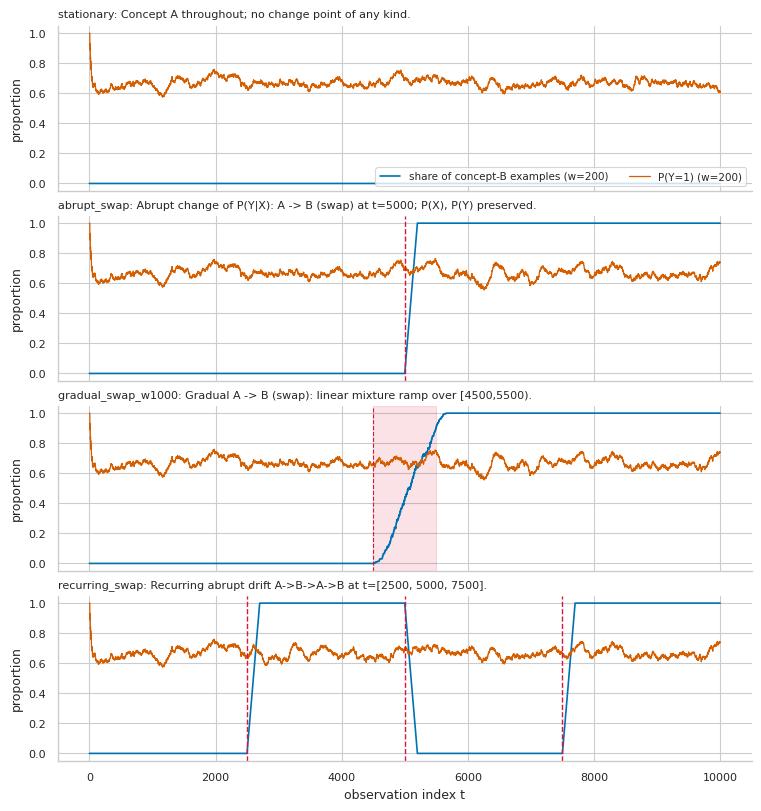

In [7]:
viz.set_style()
fig = viz.fig_stream_overview({n: demo[n] for n in ("stationary", "abrupt_swap", "gradual_swap_w%d" % cfg.stream.gradual_widths[0], "recurring_swap")}, cfg)
viz.save_figure(fig, "fig01_stream_overview", ROOT); plt.show()

**Figure 1 — what is plotted / why / axes / limits.** *Plotted:* the rolling share of concept-B examples (blue) and the rolling positive-class proportion (orange) for four generated streams, with the known drift points marked. *Why it matters:* it verifies that the stationary stream has no hidden change, that the abrupt change is a step, that the gradual change is a ramp over the stated interval and that the recurring change alternates. *Axes:* x = observation index; y = proportion in a 200-observation trailing window. *Limits:* it documents the generator only, not the learner's behaviour; the positive-class proportion is flat for `swap` drifts by construction.

**Observed pattern (auto-generated from the executed results):** stationary: share of concept-B examples in the last 200 observations = 0.00, in the first 200 = 0.00; abrupt_swap: share of concept-B examples in the last 200 observations = 1.00, in the first 200 = 0.00; gradual_swap_w1000: share of concept-B examples in the last 200 observations = 1.00, in the first 200 = 0.00; recurring_swap: share of concept-B examples in the last 200 observations = 1.00, in the first 200 = 0.00.

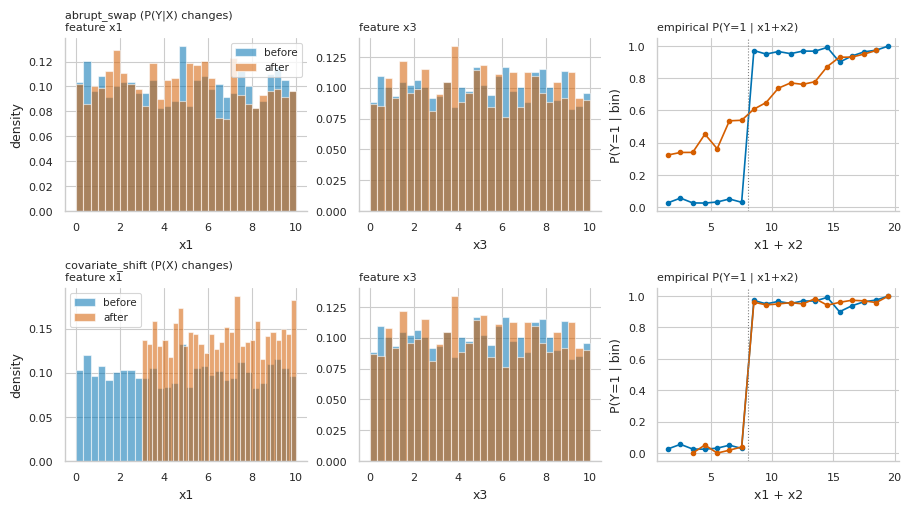

In [8]:
observed("; ".join(
    f"{n}: share of concept-B examples in the last 200 observations = {demo[n].concept[-200:].mean():.2f}, in the first 200 = {demo[n].concept[:200].mean():.2f}"
    for n in ("stationary", "abrupt_swap", "gradual_swap_w%d" % cfg.stream.gradual_widths[0], "recurring_swap")) + ".")
fig = viz.fig_distributions(demo["abrupt_swap"], demo["covariate_shift"], cfg)
viz.save_figure(fig, "fig02_distributions_before_after", ROOT); plt.show()

**Figure 2 — what is plotted / why / axes / limits.** *Plotted:* histograms of $x_1$ and $x_3$ before and after the change point, and the empirical $P(Y=1\mid x_1+x_2)$ before and after, for the concept-swap stream (top row) and the covariate-shift control (bottom row). *Why it matters:* it separates a change of $P(X)$ from a change of $P(Y\mid X)$: for `abrupt_swap` the feature histograms coincide but the conditional curve moves; for `covariate_shift` the histogram of $x_1$ moves but the conditional curve stays. *Axes:* densities (left, middle); empirical positive rate per bin of $x_1+x_2$ (right). *Limits:* bins with <10 observations are omitted; the plot is a descriptive check, not a hypothesis test.

In [9]:
sw, cv = dsum[1], dsum[0]
observed(f"for abrupt_swap the largest KS statistic on the feature marginals is {sw['max KS stat on P(X) marginals']:.3f} (no feature-distribution change) while "
         f"{sw['label disagreement with concept A rule after (noise-free labels)']:.2f} of noise-free labels disagree with the old rule; for covariate_shift the largest KS statistic is "
         f"{cv['max KS stat on P(X) marginals']:.3f} while label disagreement with the old rule is {cv['label disagreement with concept A rule after (noise-free labels)']:.2f}.")

**Observed pattern (auto-generated from the executed results):** for abrupt_swap the largest KS statistic on the feature marginals is 0.052 (no feature-distribution change) while 0.28 of noise-free labels disagree with the old rule; for covariate_shift the largest KS statistic is 0.300 while label disagreement with the old rule is 0.00.

---
## Section 8 — Dataset inspection and preprocessing (Elec2)

**Documented source.** `river.datasets.Elec2` (https://riverml.xyz/dev/api/datasets/Elec2/). The installed River docstring describes it as electricity prices in New South Wales with a binary target (price goes UP or DOWN), 45,312 observations and 8 features (`date, day, period, nswprice, nswdemand, vicprice, vicdemand, transfer`) plus the label; River's documentation cites *SPLICE-2 comparative evaluation: Electricity pricing* [13].
**Loader behaviour.** `load_elec2` tries (1) `data/raw/electricity.csv`, (2) River's dataset API (download), and otherwise raises `DatasetUnavailableError` with an alternative workflow. **It never substitutes another dataset and never fabricates data.**
**Planned preprocessing.** None beyond type conversion: the original chronological order is kept (no shuffling), `UP` is the positive class, no scaling or encoding is fitted (the source file is already min-max normalised by its publishers over the *whole* period, which is itself a possible (mild) look-ahead; see Section 19).

In [10]:
ELEC2_AVAILABLE, ELEC2_ERROR = False, None
try:
    elec_df, elec_src = load_elec2(ROOT)
    ELEC2_AVAILABLE = True
    print("Elec2 loaded from:", elec_src)
except DatasetUnavailableError as exc:
    ELEC2_ERROR = str(exc)
    print("ELEC2 NOT AVAILABLE IN THIS EXECUTION ENVIRONMENT\n" + "-" * 60 + "\n" + ELEC2_ERROR[:1800])

ELEC2 NOT AVAILABLE IN THIS EXECUTION ENVIRONMENT
------------------------------------------------------------
URLError: <urlopen error [Errno -2] Name or service not known>
Elec2 could not be loaded.
Documented source: River API  river.datasets.Elec2  (https://riverml.xyz/dev/api/datasets/Elec2/), which downloads https://maxhalford.github.io/files/datasets/electricity.zip.
Alternative workflow: obtain the same dataset on a machine with internet access (e.g. run `python -c "from river import datasets; datasets.Elec2().download()"`; the file is stored as <river_data>/Elec2/electricity.csv), copy electricity.csv to data/raw/electricity.csv inside this project (columns: date, day, period, nswprice, nswdemand, vicprice, vicdemand, transfer, class), and re-run the notebook/script.  No substitute dataset is used.


In [11]:
if ELEC2_AVAILABLE:
    print("rows, columns:", elec_df.shape, "(expected rows:", ELEC2_EXPECTED_ROWS, ")")
    display(elec_df.dtypes.to_frame("dtype").T)
    print("missing values per column:\n", elec_df.isna().sum().to_dict())
    print("duplicate rows:", int(elec_df.duplicated().sum()))
    print("class distribution:\n", elec_df["class"].value_counts(normalize=True).round(4).to_dict())
    print("'date' non-decreasing in file order:", bool(elec_df["date"].is_monotonic_increasing))
    display(elec_df.describe().T)
    fig, axes = plt.subplots(2, 4, figsize=(11, 4.5))
    for ax, c in zip(axes.ravel(), [c for c in elec_df.columns if c != "class"]):
        ax.hist(elec_df[c], bins=40, color="#0072b2"); ax.set_title(c, fontsize=8)
    viz.save_figure(fig, "figS_elec2_feature_distributions", ROOT); plt.show()
else:
    display(Markdown("**Section 8 could not be executed here** (dataset unreachable). Nothing is displayed because nothing was loaded; no placeholder statistics are shown. "
                     "To enable Sections 8 and 17: place `electricity.csv` in `data/raw/` as described in the error message above and re-run the notebook."))

**Section 8 could not be executed here** (dataset unreachable). Nothing is displayed because nothing was loaded; no placeholder statistics are shown. To enable Sections 8 and 17: place `electricity.csv` in `data/raw/` as described in the error message above and re-run the notebook.

---
## Section 9 — Prequential evaluation framework

**What the code does.** `src/experiments.py::run_prequential` implements one protocol for every policy. For each observation $t$:

1. $\hat y_t$ = `model.predict_one(x_t)` — **before** the model has seen $y_t$ (an untrained model returns `None`, recorded as class 0).
2. Log $\hat y_t, y_t, e_t=\mathbb 1[\hat y_t\ne y_t]$ (the error exists only after the label arrives).
3. Detector update with $e_t$ (drift-triggered policies only).
4. Append $(x_t,y_t)$ to the replay buffer (replay actions only; buffer holds past, already-labelled data).
5. Adaptation decision using only information up to $t$: *drift policy* — accepted alarm at $t$; *fixed policy* — $(t+1)$ is a multiple of $W$ (and $t+1<N$). On adaptation the model is replaced by a fresh one that either learns only $(x_t,y_t)$ (**reset**) or the last $R$ buffered observations including $t$ (**replay**); the detector is re-initialised. Otherwise the model learns $(x_t,y_t)$.
6. Log timing, alarms and adaptation positions.

**Information that is lost.** A *reset* loses everything learned before $t$ (the new model starts empty). *Replay* keeps only the last $R$ labelled observations; whatever lies further back is lost, and the replay window may still contain pre-drift data when the alarm is late. **Memory/time cost.** Replay needs a buffer of $R$ observations and $R$ learning steps per rebuild.

**Fairness.** All policies in a (scenario, seed) receive the same stream object in the same order; no policy sees $x_{t+1},y_{t+1}$ before step $t$ completes. This is verified by unit tests (a spy model records the call order) and by the identical-prefix check in Section 12.

In [12]:
print(inspect.getsource(run_prequential))

def run_prequential(records: Sequence[dict], labels: np.ndarray, model_factory: Callable[[], object],
                    policy: PolicySpec, adaptation: AdaptationConfig) -> RunLog:
    n = len(labels)
    pc = time.perf_counter
    model = model_factory()
    det = make_detector(policy.detector) if policy.trigger == "drift" else None
    buf: deque | None = deque(maxlen=adaptation.replay_size) if policy.action == "replay" else None
    y_pred = np.zeros(n, dtype=np.int8)
    alarms: list[int] = []
    adapts: list[int] = []
    raw_alarms = 0
    t_pred = t_learn = t_det = t_adapt = 0.0
    t_start = pc()
    for t in range(n):
        x = records[t]
        y = int(labels[t])
        a = pc()
        yp = model.predict_one(x)                      # 1. predict BEFORE learning
        b = pc()
        t_pred += b - a
        y_pred[t] = 0 if yp is None else int(yp)
        e = int(y_pred[t] != y)                        # 2. error after the label arrives
        alarm = False
        i

In [13]:
# Run the unit-test suite (toy inputs only; no downloads).  The tests verify the protocol rules listed above.
proc = subprocess.run([sys.executable, "-m", "pytest", "-q", "--no-header", "-p", "no:cacheprovider"], cwd=ROOT, capture_output=True, text=True)
print(proc.stdout[-1500:] + proc.stderr[-500:])
TESTS_PASSED = proc.returncode == 0
print("unit tests passed:", TESTS_PASSED)
assert TESTS_PASSED

...........................................                              [100%]

unit tests passed: True


---
## Section 10 — Baseline experiment (and execution of the full experimental grid)

**What the code does.** Runs the complete grid **once**: every scenario × every seed × every policy (7 primary + 4 detector-sensitivity policies), then replays each scenario's no-adaptation error stream through all six detector settings in *monitor-only* mode (Section 11), measures memory in a separate pass, and saves all raw outputs. Sections 10–14 analyse these same results; nothing is re-tuned after looking at them.

**Pre-registered definitions** (fixed in `configs/default.yaml` before running): rolling window $w=200$; reference window = 1000 observations before the change point; drift window = [onset, end + 1000); recovery = rolling accuracy ≥ 95 % of the pre-drift reference for 200 consecutive observations (sensitivity: 90 % and 98 %, Section 13); detection tolerance = 1000 observations after the end of the transition; first alarm in a window = detection, later alarms in the same window = duplicates (neither detection nor false alarm), alarms outside all windows = false alarms, no alarm = missed (delay undefined).

**Why a stationary baseline.** Rolling accuracy fluctuates even when nothing changes (binomial noise with $\sqrt{p(1-p)/w}\approx 0.02$ for $w=200$, $p\approx0.9$) and detectors can fire on noise. The stationary stream calibrates both: a dip in one window is not evidence of drift.

In [14]:
t0 = time.time()
res = run_study(cfg)
res.memory = measure_memory(cfg, "abrupt_swap" if "abrupt_swap" in cfg.run.scenarios else cfg.run.scenarios[0], build_policy_specs(cfg))
RUNTIME_MAIN_S = time.time() - t0
paths = save_study(res, ROOT, TAG)
tables = build_tables(res, cfg)
table_paths = save_tables(tables, ROOT)
print(f"\nmain study finished in {RUNTIME_MAIN_S/60:.1f} min | runs: {len(res.runs)} | monitor rows: {len(res.monitor_runs)} | failed runs: {len(res.failed)}")
assert len(res.failed) == 0, res.failed
display(res.runs.groupby("scenario", sort=False).agg(runs=("seed", "count"), seeds=("seed", "nunique")))

[   99.3s] finished scenario stationary (20 seeds x 11 policies)


[  197.4s] finished scenario covariate_shift (20 seeds x 11 policies)


[  299.2s] finished scenario abrupt_swap (20 seeds x 11 policies)


[  400.8s] finished scenario abrupt_threshold (20 seeds x 11 policies)


[  504.1s] finished scenario gradual_swap_w1000 (20 seeds x 11 policies)


[  609.0s] finished scenario gradual_swap_w2500 (20 seeds x 11 policies)


[  719.5s] finished scenario recurring_swap (20 seeds x 11 policies)



main study finished in 12.7 min | runs: 1540 | monitor rows: 840 | failed runs: 0


,runs,seeds
scenario,,
stationary,220,20
covariate_shift,220,20
abrupt_swap,220,20
abrupt_threshold,220,20
gradual_swap_w1000,220,20
gradual_swap_w2500,220,20
recurring_swap,220,20


### Baseline: no-adaptation model
**Figure 3 — stationary baseline.** *Plotted:* rolling (w=200) and cumulative prequential accuracy of the non-adapting Hoeffding tree on the stationary stream, mean ± SD over seeds. *Why:* it shows the learning curve and the size of ordinary fluctuations that any detector must tolerate. *Axes:* x = observation index, y = accuracy. *Limits:* with 5 % label noise the best attainable accuracy is about 0.95; the curve describes this learner and generator only.

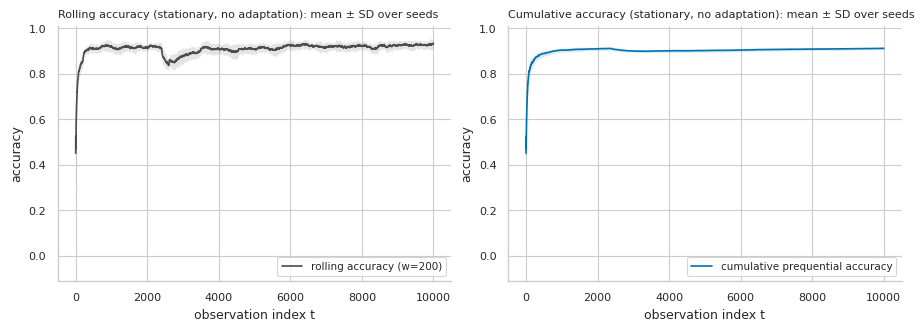

**Observed pattern (auto-generated from the executed results):** on the stationary stream the final cumulative accuracy is 0.912 (SD across 20 seeds 0.005); after the first quarter of the stream the rolling accuracy of a single run varies with SD 0.027 around its own mean, and individual rolling values range from 0.780 to 0.990 although nothing changes.

In [15]:
fig = viz.fig_stationary_baseline(res, cfg); viz.save_figure(fig, "fig03_stationary_baseline", ROOT); plt.show()
st_none = res.runs[(res.runs.scenario == "stationary") & (res.runs.policy == "none")]
M = np.vstack([rolling_mean(1 - e.astype(float), cfg.eval.rolling_window) for (sc, p, _), e in res.errors.items() if sc == "stationary" and p == "none"])
late = M[:, cfg.stream.length // 4:]
observed(f"on the stationary stream the final cumulative accuracy is {st_none['overall_acc'].mean():.3f} (SD across {len(st_none)} seeds {st_none['overall_acc'].std():.3f}); "
         f"after the first quarter of the stream the rolling accuracy of a single run varies with SD {late.std(axis=1).mean():.3f} around its own mean, "
         f"and individual rolling values range from {late.min():.3f} to {late.max():.3f} although nothing changes.")

**Figure 4 — cumulative accuracy with known drift locations.** *Plotted:* cumulative prequential accuracy of the **no-adaptation** model for every scenario, mean ± SD over seeds, with the known change points (dashed red), transition intervals (shaded) and the covariate-shift point (dotted purple). *Why:* it shows when and how strongly performance bends away from the learning curve. *Axes:* x = observation index, y = accuracy since the start. *Limits:* cumulative accuracy reacts slowly (it averages the whole history), so the *timing* of degradation is read from Figure 5.

**Figure 5 — rolling error rate.** *Plotted:* trailing 200-observation error rate for the same runs. *Why:* local view of degradation and recovery used for the recovery definition. *Axes:* y = error rate in the window (lower is better). *Limits:* the window length trades noise for delay.

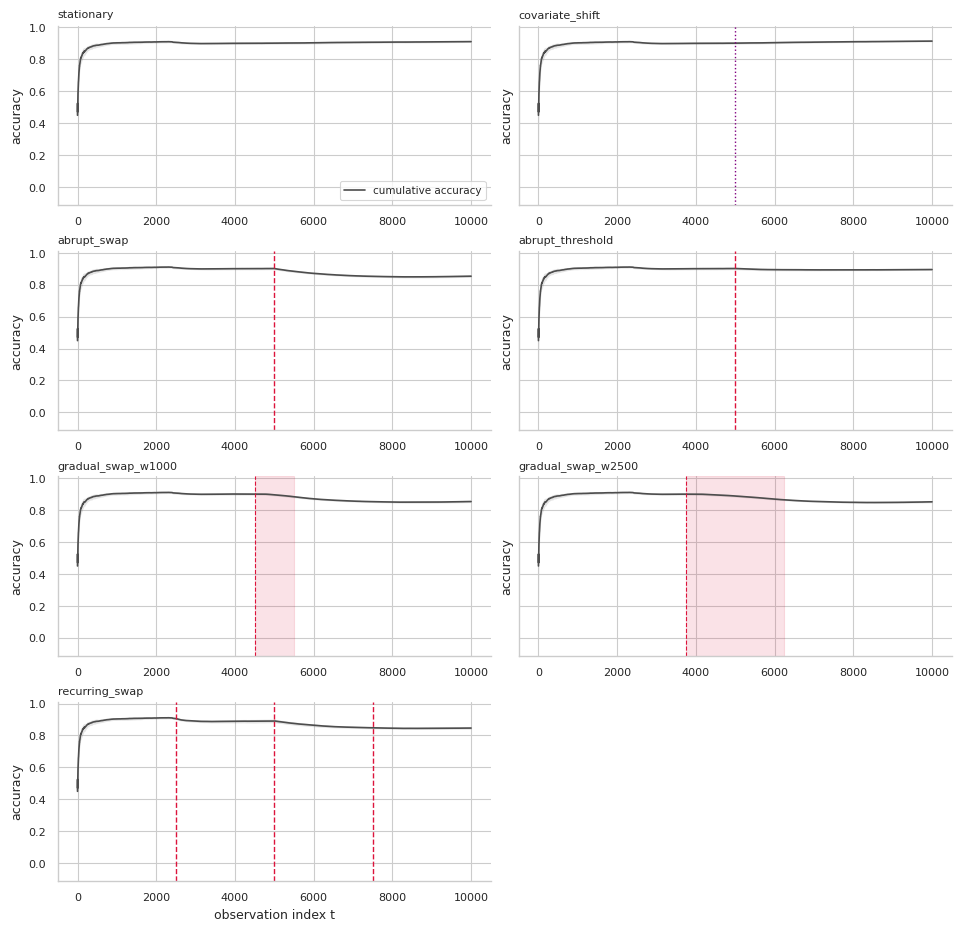

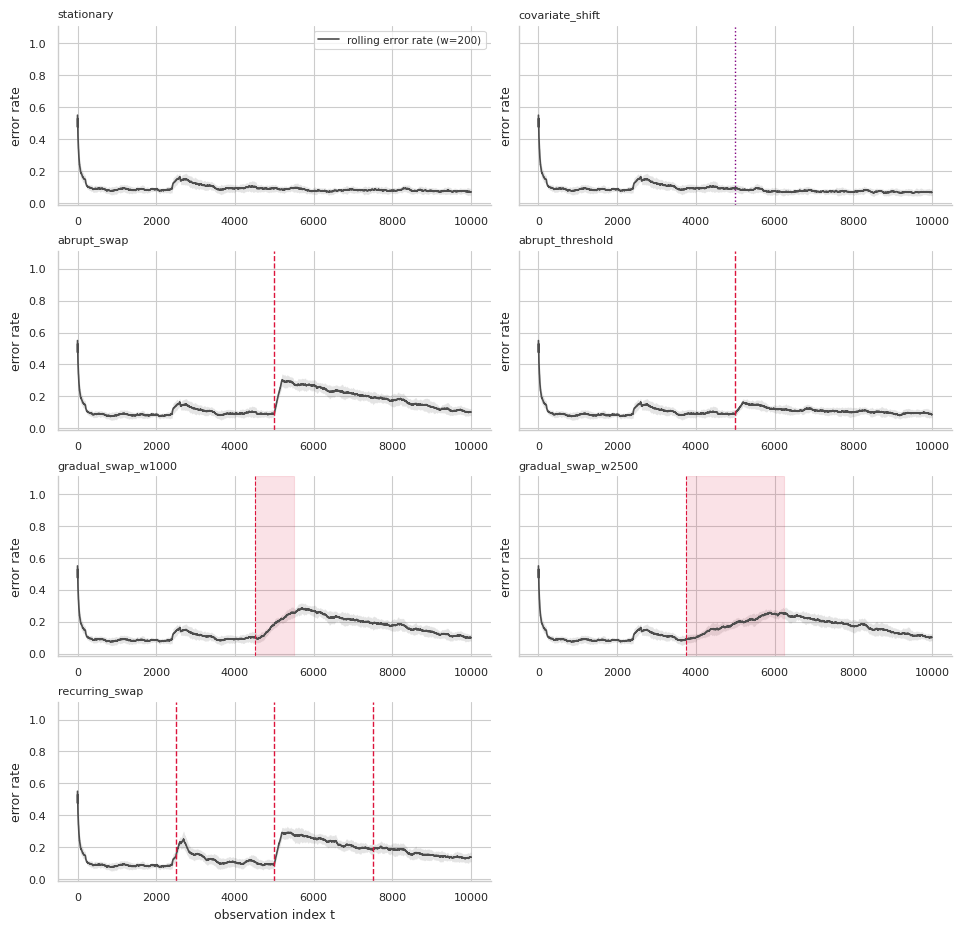

,pre_acc_mean,pre_acc_sd,drift_window_acc_mean,drift_window_acc_sd,post_acc_mean,acc_drop_mean,n_runs
scenario,,,,,,,
stationary,0.9067,0.0150,0.9149,0.0130,0.9149,-0.0083,20
covariate_shift,0.9067,0.0150,0.9196,0.0085,0.9196,-0.0129,20
abrupt_swap,0.9067,0.0150,0.7181,0.0150,0.7181,0.1887,20
abrupt_threshold,0.9067,0.0150,0.8586,0.0124,0.8586,0.0481,20
gradual_swap_w1000,0.9066,0.0171,0.7755,0.0130,0.7433,0.1311,20
gradual_swap_w2500,0.8954,0.0179,0.8014,0.0057,0.7792,0.0940,20
recurring_swap,0.8694,0.0069,0.7945,0.0143,0.7945,0.0749,20


**Observed pattern (auto-generated from the executed results):** stationary: pre-drift 0.907 → drift window 0.915 (mean drop -0.008); covariate_shift: pre-drift 0.907 → drift window 0.920 (mean drop -0.013); abrupt_swap: pre-drift 0.907 → drift window 0.718 (mean drop +0.189); abrupt_threshold: pre-drift 0.907 → drift window 0.859 (mean drop +0.048); gradual_swap_w1000: pre-drift 0.907 → drift window 0.775 (mean drop +0.131); gradual_swap_w2500: pre-drift 0.895 → drift window 0.801 (mean drop +0.094); recurring_swap: pre-drift 0.869 → drift window 0.795 (mean drop +0.075). The first two rows labelled stationary and covariate_shift are control streams: their 'change point' is the stream midpoint / the covariate-shift point, not a concept change.

In [16]:
fig = viz.fig_accuracy_with_drift(res, cfg, "accuracy"); viz.save_figure(fig, "fig04_accuracy_with_drift", ROOT); plt.show()
fig = viz.fig_accuracy_with_drift(res, cfg, "error"); viz.save_figure(fig, "fig05_rolling_error_with_drift", ROOT); plt.show()
ap = tables["adaptation_performance"]; ap0 = ap[ap["policy"] == "none"].set_index("scenario")
display(ap0[["pre_acc_mean", "pre_acc_sd", "drift_window_acc_mean", "drift_window_acc_sd", "post_acc_mean", "acc_drop_mean", "n_runs"]])
observed("; ".join(f"{sc}: pre-drift {r.pre_acc_mean:.3f} → drift window {r.drift_window_acc_mean:.3f} (mean drop {r.acc_drop_mean:+.3f})" for sc, r in ap0.iterrows()) +
         ". The first two rows labelled stationary and covariate_shift are control streams: their 'change point' is the stream midpoint / the covariate-shift point, not a concept change.")

---
## Section 11 — Drift detector experiments

**What the code does.** The no-adaptation error stream of each (scenario, seed) is fed to **fresh** ADWIN and Page-Hinkley instances at three a-priori sensitivity levels (*monitor-only* mode: one shared prequential error stream, detectors attached to a separate monitoring component). Because the model never changes in this mode, all six detectors see exactly the same signal.

**Detector signal.** Binary error indicator $e_t$ (1 = misclassified), computed after the label arrives.

**Parameters (not equivalent).**
| Detector | Parameter | Meaning | sensitive / **default** / conservative |
|---|---|---|---|
| ADWIN | `delta` | confidence parameter of the sub-window mean test; larger ⇒ alarms on weaker evidence | 0.02 / **0.002** / 0.0002 |
| Page-Hinkley | `threshold` ($\lambda$) | bound on the cumulative deviation statistic; smaller ⇒ alarms sooner | 25 / **50** / 100 |
| Page-Hinkley | `delta`, `alpha`, `min_instances`, `mode` | tolerated drift per step (0.005), forgetting factor (0.9999), warm-up (30), `up` (increases only) | fixed |

Defaults are River's library defaults and were fixed *before* any result was seen; the other two levels bracket them by an order of magnitude. No threshold was tuned on outcomes.

**Alarm-matching rule** (see `src/evaluation.py`): window of event $i$ = [onset$_i$, min(end$_i$ + 1000, onset$_{i+1}$, N)); first alarm in a window ⇒ detection with delay = alarm − onset$_i$ (and alarm − end$_i$, negative if inside the transition); further alarms in the window = duplicates (not counted twice); alarms elsewhere = false alarms; windows without alarm = missed (delay undefined, **never imputed**). False alarms are normalised per 1000 observations outside all windows.

In [17]:
display(tables["detector_performance"].round(3))
display(tables["detection_delay"].round(1))
display(tables["false_alarms_and_missed"].round(3))

,scenario,detector_name,n_alarms_mean,n_alarms_sd,n_raw_alarms_mean,n_raw_alarms_sd,n_detected_mean,n_detected_sd,detection_recall_mean,detection_recall_sd,alarm_precision_mean,alarm_precision_sd,n_runs
0,stationary,adwin_sensitive,0.65,0.489,1.10,0.912,0.00,0.000,NaN,NaN,0.000,0.000,20
1,stationary,adwin_default,0.25,0.444,0.55,0.686,0.00,0.000,NaN,NaN,0.000,0.000,20
2,stationary,adwin_conservative,0.15,0.366,0.25,0.444,0.00,0.000,NaN,NaN,0.000,0.000,20
3,stationary,ph_sensitive,0.95,0.224,0.95,0.224,0.00,0.000,NaN,NaN,0.000,0.000,20
4,stationary,ph_default,0.30,0.470,0.30,0.470,0.00,0.000,NaN,NaN,0.000,0.000,20
5,stationary,ph_conservative,0.00,0.000,0.00,0.000,0.00,0.000,NaN,NaN,NaN,NaN,20
6,covariate_shift,adwin_sensitive,0.65,0.489,1.45,0.759,0.00,0.000,NaN,NaN,0.000,0.000,20
7,covariate_shift,adwin_default,0.25,0.444,0.90,0.553,0.00,0.000,NaN,NaN,0.000,0.000,20
8,covariate_shift,adwin_conservative,0.15,0.366,0.50,0.513,0.00,0.000,NaN,NaN,0.000,0.000,20
9,covariate_shift,ph_sensitive,1.00,0.324,1.00,0.324,0.00,0.000,NaN,NaN,0.000,0.000,20


,scenario,detector_name,n_runs,runs_with_detection,delay_mean,delay_sd,delay_median,delay_q25,delay_q75,delay_from_end_mean
0,abrupt_swap,adwin_sensitive,20,20,75.8,36.4,55.0,55.0,87.0,75.8
1,abrupt_swap,adwin_default,20,20,107.8,41.9,87.0,87.0,119.0,107.8
2,abrupt_swap,adwin_conservative,20,20,130.2,49.0,119.0,87.0,151.0,130.2
3,abrupt_swap,ph_sensitive,20,20,109.6,39.4,97.0,85.8,127.0,109.6
4,abrupt_swap,ph_default,20,20,184.5,82.7,183.5,141.0,220.2,184.5
5,abrupt_swap,ph_conservative,20,20,430.0,86.4,411.5,370.8,494.8,430.0
6,abrupt_threshold,adwin_sensitive,20,12,348.3,188.5,295.0,207.0,439.0,348.3
7,abrupt_threshold,adwin_default,20,5,567.0,241.6,471.0,407.0,567.0,567.0
8,abrupt_threshold,adwin_conservative,20,4,679.0,185.7,615.0,583.0,711.0,679.0
9,abrupt_threshold,ph_sensitive,20,16,416.9,179.7,348.0,301.5,512.5,416.9


,scenario,detector_name,n_false_alarms_mean,n_false_alarms_sd,false_alarms_per_1000_mean,false_alarms_per_1000_sd,n_missed_mean,n_missed_sd,n_duplicates_mean,n_duplicates_sd,alarms_after_shift_window_mean,alarms_after_shift_window_sd,n_runs
0,stationary,adwin_sensitive,0.65,0.489,0.065,0.049,0.00,0.000,0.00,0.000,NaN,NaN,20
1,stationary,adwin_default,0.25,0.444,0.025,0.044,0.00,0.000,0.00,0.000,NaN,NaN,20
2,stationary,adwin_conservative,0.15,0.366,0.015,0.037,0.00,0.000,0.00,0.000,NaN,NaN,20
3,stationary,ph_sensitive,0.95,0.224,0.095,0.022,0.00,0.000,0.00,0.000,NaN,NaN,20
4,stationary,ph_default,0.30,0.470,0.030,0.047,0.00,0.000,0.00,0.000,NaN,NaN,20
5,stationary,ph_conservative,0.00,0.000,0.000,0.000,0.00,0.000,0.00,0.000,NaN,NaN,20
6,covariate_shift,adwin_sensitive,0.65,0.489,0.065,0.049,0.00,0.000,0.00,0.000,0.0,0.0,20
7,covariate_shift,adwin_default,0.25,0.444,0.025,0.044,0.00,0.000,0.00,0.000,0.0,0.0,20
8,covariate_shift,adwin_conservative,0.15,0.366,0.015,0.037,0.00,0.000,0.00,0.000,0.0,0.0,20
9,covariate_shift,ph_sensitive,1.00,0.324,0.100,0.032,0.00,0.000,0.00,0.000,0.0,0.0,20


**Figures 6 and 7 — detection timelines.** *Plotted:* for one seed (the first), the rolling error rate of the non-adapting model on `abrupt_swap` and the accepted alarms (coloured vertical lines) of ADWIN (Fig. 6) and Page-Hinkley (Fig. 7) at each sensitivity level; the red dashed line is the known drift point. *Why:* it makes alarm timing, duplicates and false alarms visible for a concrete run. *Axes:* x = observation index, y = rolling error. *Limits:* a single seed illustrates mechanics; statements about detector behaviour must rely on the multi-seed tables and figures that follow.

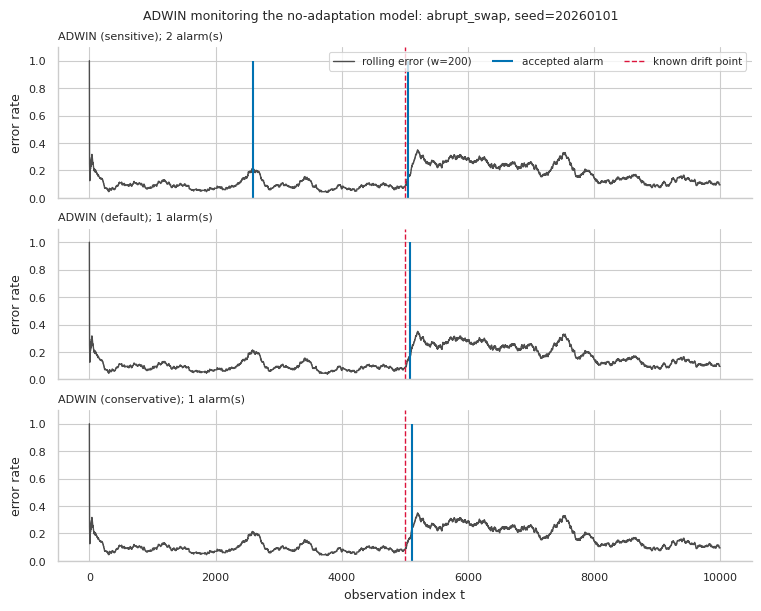

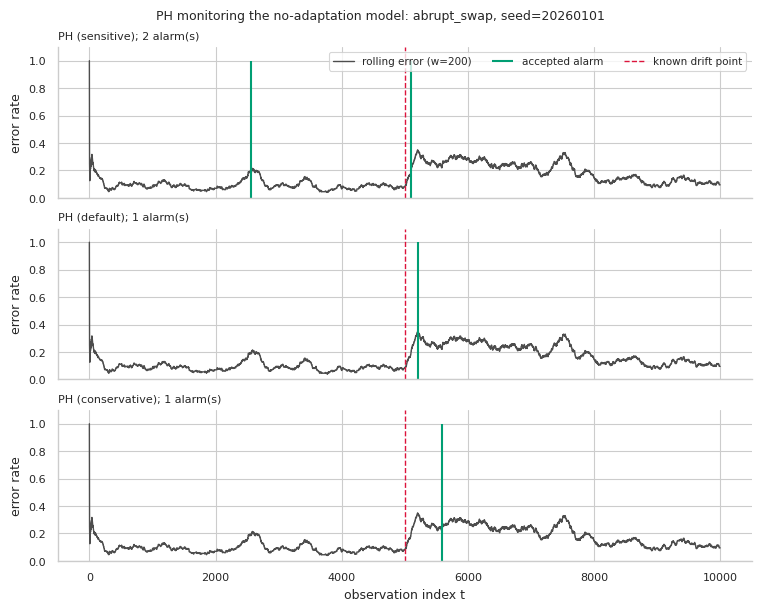

**Observed pattern (auto-generated from the executed results):** for abrupt_swap, seed 20260101, drift onset at t=5000: adwin_conservative alarms at [5119]; adwin_default alarms at [5087]; adwin_sensitive alarms at [2591, 5055]; ph_conservative alarms at [5594]; ph_default alarms at [5202]; ph_sensitive alarms at [2564, 5099].

In [18]:
sc_demo = "abrupt_swap" if "abrupt_swap" in cfg.run.scenarios else cfg.run.scenarios[0]
fig = viz.fig_detector_timeline(res, cfg, "adwin", sc_demo); viz.save_figure(fig, "fig06_adwin_timeline", ROOT); plt.show()
fig = viz.fig_detector_timeline(res, cfg, "ph", sc_demo); viz.save_figure(fig, "fig07_pagehinkley_timeline", ROOT); plt.show()
sd0 = cfg.seeds()[0]; onset0 = specs[sc_demo].onsets[0]
al = res.alarm_log[(res.alarm_log.scenario == sc_demo) & (res.alarm_log.seed == sd0) & res.alarm_log.policy.str.startswith("monitor:")]
observed(f"for {sc_demo}, seed {sd0}, drift onset at t={onset0}: " + "; ".join(
    f"{p.replace('monitor:', '')} alarms at {sorted(g['t'].tolist())}" for p, g in al.groupby('policy')) + ".")

**Figure 8 — detector comparison across drift types.** *Plotted:* detection rate (fraction of known events detected) and number of accepted alarms per run, default settings, for each scenario with concept drift; bars = mean, whiskers = 95 % CI over seeds. *Why:* separates *whether* a drift is found from *how noisy* the detector is. *Limits:* the detection rate is bounded by the tolerance window; recurring drift contains three events per run.

**Figure 9 — detection delay.** *Plotted:* box plots of detection delay (observations after onset) for detected events only, for all six detector settings. *Why:* delay is only defined when detection happens, so Figure 8 must be read alongside it. *Limits:* survivorship — settings that miss hard cases can look fast.

**Figure 10 — false-alarm comparison.** *Plotted:* false alarms per 1000 observations outside the detection windows, all scenarios including the stationary and covariate-shift controls. *Why:* the stationary stream isolates pure noise-triggered alarms; the covariate-shift stream shows reactions to a non-concept change. *Limits:* rates are small; confidence intervals matter.

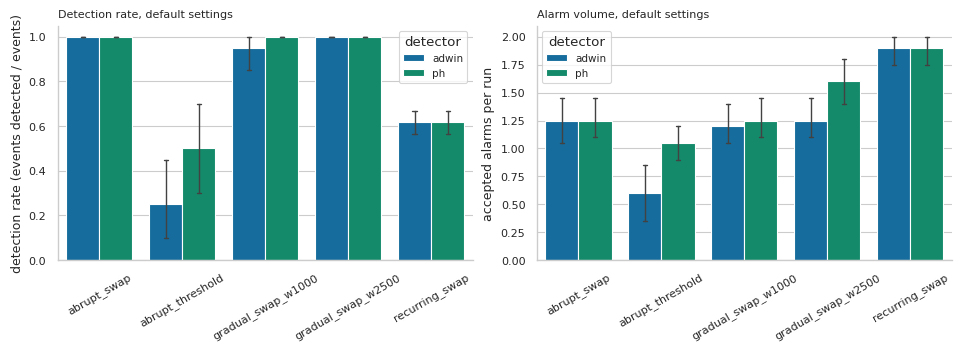

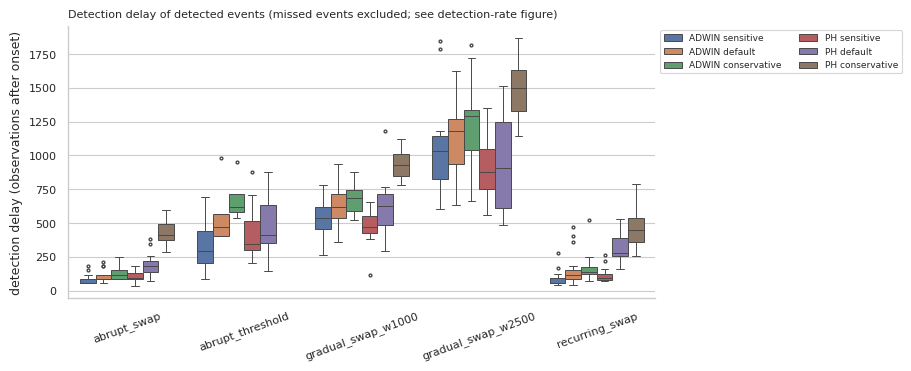

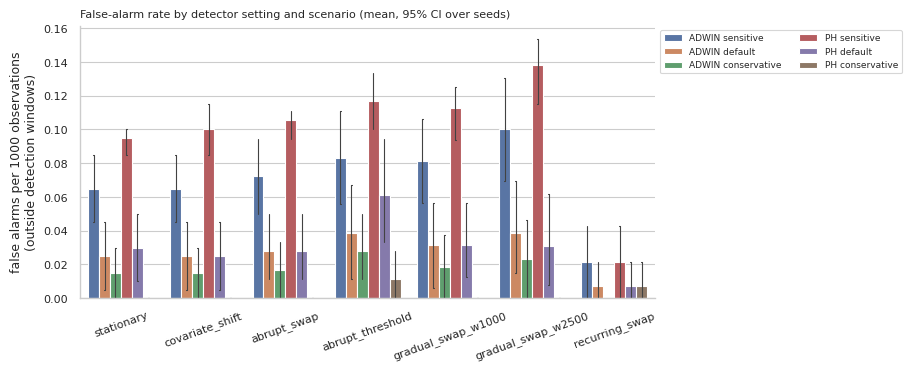

**Observed pattern (auto-generated from the executed results):** alarms per run on the stationary stream (all are false alarms by construction): adwin_conservative: 0.15, adwin_default: 0.25, adwin_sensitive: 0.65, ph_conservative: 0.00, ph_default: 0.30, ph_sensitive: 0.95; mean alarms within the tolerance window after the covariate-shift point (a non-concept change): adwin_conservative: 0.00, adwin_default: 0.00, adwin_sensitive: 0.00, ph_conservative: 0.00, ph_default: 0.00, ph_sensitive: 0.00.

In [19]:
fig = viz.fig_detector_comparison(res, cfg); viz.save_figure(fig, "fig08_detector_comparison", ROOT); plt.show()
fig = viz.fig_detection_delay(res, cfg); viz.save_figure(fig, "fig09_detection_delay", ROOT); plt.show()
fig = viz.fig_false_alarms(res, cfg); viz.save_figure(fig, "fig10_false_alarms", ROOT); plt.show()
m = res.monitor_runs
g = m.groupby(["detector", "level"]).agg(rate=("false_alarms_per_1000", "mean"), delay=("detection_delay", "mean"), det=("detection_recall", "mean")).reset_index()
stat = m[m.scenario == "stationary"].groupby("detector_name")["n_alarms"].mean()
cov = m[m.scenario == "covariate_shift"].groupby("detector_name")["alarms_after_shift_window"].mean() if "covariate_shift" in set(m.scenario) else pd.Series(dtype=float)
observed("alarms per run on the stationary stream (all are false alarms by construction): " + ", ".join(f"{k}: {v:.2f}" for k, v in stat.items()) +
         ("; mean alarms within the tolerance window after the covariate-shift point (a non-concept change): " + ", ".join(f"{k}: {v:.2f}" for k, v in cov.items()) if len(cov) else "") + ".")

---
## Section 12 — Adaptation and retraining experiments

**Policies compared** (identical streams, order and evaluation rules):

| Policy | Trigger | Action on trigger | State kept | Cost drivers |
|---|---|---|---|---|
| `none` | – | – | everything the incremental learner has learned | learner only |
| `fixed_reset` | every $W$ observations | fresh empty model | nothing | $\lfloor N/W\rfloor$ resets regardless of drift |
| `fixed_replay` | every $W$ observations | fresh model trained on last $R$ observations | last $R$ labelled observations | buffer + $R$ updates per rebuild |
| `adwin_reset`, `ph_reset` | accepted detector alarm | fresh empty model; detector re-initialised | nothing | detector update per observation; resets on every (also false) alarm |
| `adwin_replay`, `ph_replay` | accepted detector alarm | fresh model trained on last $R$ observations | last $R$ observations | as above + buffer |

Fixed window $W=2000$ and replay size $R=500$ were set a priori. The replay buffer contains only observations with index ≤ the current one (no look-ahead). For drift-triggered replay the buffer may still contain pre-drift data when the alarm is late — this is part of the policy being evaluated, not a defect.

**Fair-comparison protocol check.** Below, for every (scenario, seed) we verify that each policy's prediction errors are *identical* to the no-adaptation errors up to its first adaptation (same model, same data, same order): if any policy had seen different data or future information, the prefixes would differ.

In [20]:
# Fair-comparison / leakage check: identical prediction-error prefix up to the first adaptation of each policy.
ev = res.alarm_log[res.alarm_log.event == "adaptation"]
first_adapt = ev.groupby(["scenario", "policy", "seed"])["t"].min().to_dict()
bad, n_checked = [], 0
for (sc, pol, seed), err in res.errors.items():
    if pol == "none": continue
    base = res.errors[(sc, "none", seed)]
    k = first_adapt.get((sc, pol, seed), len(err) - 1)       # errors up to and including step k are produced before adaptation takes effect
    n_checked += 1
    if not np.array_equal(err[:k + 1], base[:k + 1]): bad.append((sc, pol, seed))
print(f"checked {n_checked} policy runs; runs with differing pre-adaptation prefix: {len(bad)}")
assert not bad
FAIRNESS_OK = not bad
# adaptation events only at documented trigger conditions
W = cfg.adaptation.fixed_window
fx = ev[ev.policy.str.startswith("fixed")]
assert ((fx["t"] + 1) % W == 0).all(), "fixed-window adaptation off schedule"
dr = ev[~ev.policy.str.startswith("fixed")]
al_ = res.alarm_log[res.alarm_log.event == "alarm"]
merged = dr.merge(al_, on=["scenario", "policy", "seed", "t"], how="left", suffixes=("", "_a"))
assert merged["event_a"].notna().all(), "drift adaptation without an accepted alarm"
TRIGGERS_OK = True
print("fixed-window adaptations only at multiples of W; every drift-triggered adaptation coincides with an accepted alarm: True")

checked 1400 policy runs; runs with differing pre-adaptation prefix: 0
fixed-window adaptations only at multiples of W; every drift-triggered adaptation coincides with an accepted alarm: True


In [21]:
display(tables["adaptation_performance"].round(3))
display(tables["recovery_time"].round(2))
display(tables["computational_cost"].round(3))

,scenario,policy,pre_acc_mean,pre_acc_sd,drift_window_acc_mean,drift_window_acc_sd,post_acc_mean,post_acc_sd,acc_drop_mean,acc_drop_sd,overall_acc_mean,overall_acc_sd,n_runs
0,stationary,none,0.907,0.015,0.915,0.013,0.915,0.013,-0.008,0.014,0.912,0.005,20
1,stationary,fixed_reset,0.898,0.011,0.912,0.013,0.912,0.013,-0.014,0.018,0.907,0.003,20
2,stationary,fixed_replay,0.913,0.013,0.903,0.013,0.903,0.013,0.011,0.017,0.910,0.003,20
3,stationary,adwin_reset,0.906,0.016,0.905,0.020,0.905,0.020,0.001,0.021,0.909,0.006,20
4,stationary,adwin_replay,0.902,0.016,0.911,0.013,0.911,0.013,-0.009,0.013,0.910,0.006,20
5,stationary,ph_reset,0.906,0.016,0.907,0.020,0.907,0.020,-0.001,0.024,0.909,0.007,20
6,stationary,ph_replay,0.904,0.015,0.910,0.017,0.910,0.017,-0.006,0.016,0.910,0.006,20
7,covariate_shift,none,0.907,0.015,0.920,0.008,0.920,0.008,-0.013,0.014,0.915,0.004,20
8,covariate_shift,fixed_reset,0.898,0.011,0.917,0.012,0.917,0.012,-0.019,0.017,0.909,0.003,20
9,covariate_shift,fixed_replay,0.913,0.013,0.912,0.012,0.912,0.012,0.002,0.014,0.913,0.003,20


,scenario,policy,recovery_time_capped_mean,recovery_time_capped_sd,recovery_rate_mean,recovery_rate_sd,degraded_rate_mean,degraded_rate_sd,n_runs,recovery_time_capped_median
0,stationary,none,204.60,25.04,1.00,0.00,0.45,0.51,20,199.00
1,stationary,fixed_reset,243.00,131.26,1.00,0.00,0.85,0.37,20,199.00
2,stationary,fixed_replay,264.70,213.64,1.00,0.00,1.00,0.00,20,199.00
3,stationary,adwin_reset,277.20,171.05,1.00,0.00,0.60,0.50,20,199.00
4,stationary,adwin_replay,204.60,25.04,1.00,0.00,0.55,0.51,20,199.00
5,stationary,ph_reset,288.70,208.55,1.00,0.00,0.60,0.50,20,199.00
6,stationary,ph_replay,229.55,96.02,1.00,0.00,0.55,0.51,20,199.00
7,covariate_shift,none,199.00,0.00,1.00,0.00,0.25,0.44,20,199.00
8,covariate_shift,fixed_reset,199.00,0.00,1.00,0.00,0.75,0.44,20,199.00
9,covariate_shift,fixed_replay,199.00,0.00,1.00,0.00,0.85,0.37,20,199.00


,scenario,policy,us_per_obs_mean,us_per_obs_sd,time_total_s_mean,time_total_s_sd,time_detector_s_mean,time_detector_s_sd,time_adapt_s_mean,time_adapt_s_sd,n_adaptations_mean,n_adaptations_sd,n_runs,peak_kib_mean
0,stationary,none,41.497,2.651,0.415,0.027,0.000,0.000,0.000,0.000,0.00,0.000,20,237.796
1,stationary,fixed_reset,38.871,2.743,0.389,0.027,0.000,0.000,0.001,0.000,4.00,0.000,20,81.038
2,stationary,fixed_replay,44.176,3.549,0.442,0.035,0.000,0.000,0.047,0.006,4.00,0.000,20,83.165
3,stationary,adwin_reset,43.658,3.642,0.437,0.036,0.015,0.001,0.000,0.001,0.35,0.745,20,122.280
4,stationary,adwin_replay,45.419,4.530,0.454,0.045,0.016,0.002,0.005,0.010,0.40,0.754,20,113.564
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
72,recurring_swap,ph_replay,51.192,8.066,0.512,0.081,0.018,0.002,0.038,0.008,2.85,0.366,20,126.272
73,recurring_swap,adwin_sensitive_replay,53.461,7.642,0.535,0.076,0.017,0.003,0.039,0.006,2.95,0.224,20,NaN
74,recurring_swap,adwin_conservative_replay,52.885,8.765,0.529,0.088,0.017,0.002,0.040,0.009,2.90,0.308,20,NaN
75,recurring_swap,ph_sensitive_replay,49.492,4.152,0.495,0.042,0.017,0.001,0.038,0.005,3.05,0.224,20,NaN


**Figure 11 — adaptation-policy performance curves.** *Plotted:* trailing 200-observation accuracy averaged over seeds, one panel per concept-drift scenario, one line per primary policy; known drift points and transitions are marked. *Why:* shows the shape of degradation and recovery for each policy on identical data. *Axes:* x = observation index, y = rolling accuracy (zoomed to 0.55–1). *Limits:* means over seeds hide run-to-run variability (see Figures 12 and 14); lines overlap before the first adaptation by construction.

**Figure 12 — recovery time.** *Plotted:* distribution over seeds of the (event-averaged) time from drift onset until the rolling accuracy has recovered to ≥95 % of its pre-drift reference and stayed there for 200 observations. Runs that never recover are **right-censored** at the horizon (next onset or end of stream) — they are not given an invented recovery time. *Why:* quantifies how long the model stays unreliable. *Axes:* y = observations (minimum attainable ≈ 199 because the rolling window must lie entirely after the onset). *Limits:* the value depends on the threshold and window (sensitivity in Section 13).

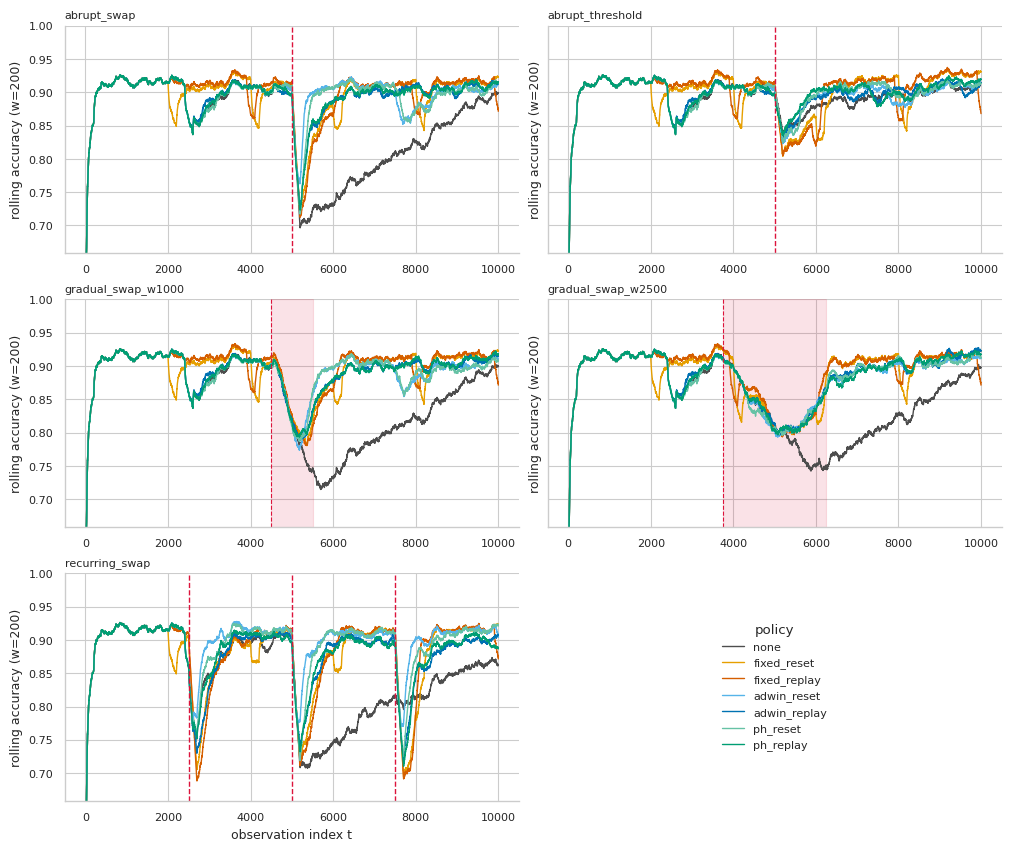

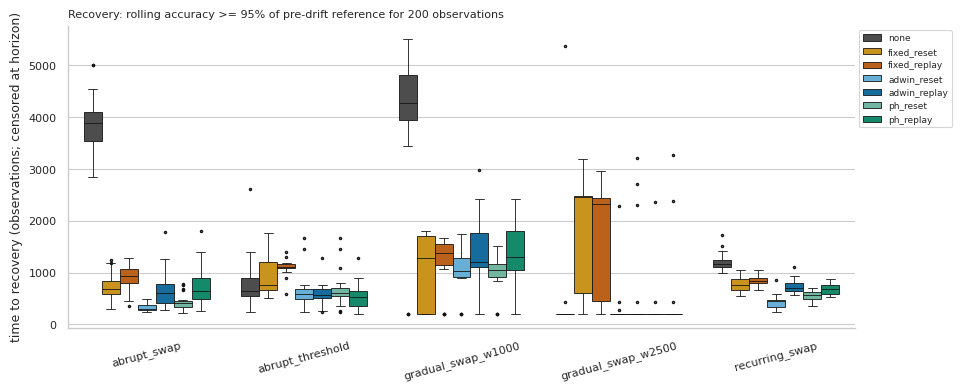

**Observed pattern (auto-generated from the executed results):** fraction of runs in which the model did recover (recovery rate < 1 listed only): abrupt_swap/none: 0.90; gradual_swap_w1000/none: 0.85; recurring_swap/none: 0.70.

In [22]:
fig = viz.fig_policy_curves(res, cfg); viz.save_figure(fig, "fig11_policy_curves", ROOT); plt.show()
fig = viz.fig_recovery_time(res, cfg); viz.save_figure(fig, "fig12_recovery_time", ROOT); plt.show()
rc = tables["recovery_time"]
notrec = rc[rc.recovery_rate_mean < 1][["scenario", "policy", "recovery_rate_mean"]]
observed("fraction of runs in which the model did recover (recovery rate < 1 listed only): " +
         ("; ".join(f"{r.scenario}/{r.policy}: {r.recovery_rate_mean:.2f}" for r in notrec.itertuples()) if len(notrec) else "all runs recovered within their horizon") + ".")

---
## Section 13 — Controlled experiments and sensitivity analyses

**Grid actually executed (Section 10).** 7 scenarios (drift type × magnitude/transition width) × 11 policies (detector choice × sensitivity × action) × `n_seeds` independent seeds; the experiment parameters of every run (scenario, kind, seed, model, trigger, action, detector, level) are stored in `results/raw/<tag>_runs.csv`, together with the configuration snapshot in `results/logs/<tag>_config.json`. Drift **magnitude** is varied by the concept change (`swap` disagreement ≈ 0.30 vs `threshold` ≈ 0.13) and the **transition duration** by the gradual widths. Nothing in this grid was re-tuned after seeing test outcomes: all parameters are from the configuration fixed in advance; the sensitivity levels are reported as sensitivity levels, not as "selected best".

**Additional controlled analyses below:** (a) recovery-definition sensitivity (90 %, 95 %, 98 %), (b) model-effect sub-experiment (Gaussian Naive Bayes vs Hoeffding tree, two scenarios, none vs ADWIN-replay), (c) memory (separate tracemalloc pass).

In [23]:
display(tables["recovery_sensitivity"].round(2).pivot_table(index=["scenario", "policy"], columns="fraction", values="recovery_time_capped_mean").round(0))
rs = tables["recovery_sensitivity"]
tight = rs.pivot_table(index=["scenario", "policy"], columns="fraction", values="recovery_time_capped_mean")
order_ok = (tight[0.90] <= tight[0.95] + 1e-9).mean(), (tight[0.95] <= tight[0.98] + 1e-9).mean()
observed(f"stricter recovery thresholds give longer or equal censored recovery times in {order_ok[0]*100:.0f}% (90→95 %) and {order_ok[1]*100:.0f}% (95→98 %) of scenario/policy cells; "
         "differences between policies that persist across the three thresholds are less likely to be artefacts of the 95 % choice.")

fraction                           0.90    0.95    0.98
scenario           policy                              
abrupt_swap        adwin_replay   422.0   678.0  1341.0
                   fixed_replay   596.0   907.0  1225.0
                   none          2714.0  3896.0  4547.0
                   ph_replay      404.0   736.0  1405.0
abrupt_threshold   adwin_replay   259.0   591.0  1098.0
                   fixed_replay   619.0  1104.0  1434.0
                   none           297.0   800.0  1976.0
                   ph_replay      266.0   550.0   872.0
gradual_swap_w1000 adwin_replay   508.0  1387.0  1865.0
                   fixed_replay   256.0  1183.0  1636.0
                   none          1254.0  3882.0  4737.0
                   ph_replay      520.0  1332.0  2042.0
gradual_swap_w2500 adwin_replay   199.0   593.0  1631.0
                   fixed_replay   405.0  1665.0  2831.0
                   none           199.0   470.0  2852.0
                   ph_replay      199.0   473.0  1602.0
recurring_swap     adwin_replay   457.0   736.0  1145.0
                   fixed_replay   576.0   841.0  1117.0
                   none           907.0  1220.0  1400.0
                   ph_replay      403.0   681.0  1050.0

**Observed pattern (auto-generated from the executed results):** stricter recovery thresholds give longer or equal censored recovery times in 100% (90→95 %) and 100% (95→98 %) of scenario/policy cells; differences between policies that persist across the three thresholds are less likely to be artefacts of the 95 % choice.

In [24]:
# (b) model-effect sub-experiment: separate runs, same seeds, same streams
nb_seeds = cfg.seeds()[: (10 if PROFILE == "full" else 2)]
nb_scen = [s for s in ("stationary", "abrupt_swap") if s in cfg.run.scenarios]
pols = {k: v for k, v in build_policy_specs(cfg).items() if k in ("none", "adwin_replay")}
t0 = time.time()
res_nb = run_study(cfg, scenarios=nb_scen, policies=pols, seeds=nb_seeds, model_name="gaussian_nb", monitor=False, progress=False)
res_ht = res.runs[res.runs.scenario.isin(nb_scen) & res.runs.policy.isin(pols) & res.runs.seed.isin(nb_seeds)]
mc = pd.concat([res_ht, res_nb.runs]).groupby(["scenario", "model", "policy"]).agg(
    n_runs=("seed", "count"), overall_acc=("overall_acc", "mean"), drift_window_acc=("drift_window_acc", "mean"),
    n_adaptations=("n_adaptations", "mean"), us_per_obs=("us_per_obs", "mean")).reset_index()
display(mc.round(3)); mc.to_csv(ROOT / "results" / "tables" / "model_comparison.csv", index=False)
print(f"model sub-experiment finished in {time.time()-t0:.0f}s; failed: {len(res_nb.failed)}")

,scenario,model,policy,n_runs,overall_acc,drift_window_acc,n_adaptations,us_per_obs
0,abrupt_swap,gaussian_nb,adwin_replay,10,0.901,0.818,1.0,203.433
1,abrupt_swap,gaussian_nb,none,10,0.835,0.709,0.0,182.561
2,abrupt_swap,hoeffding_tree,adwin_replay,10,0.897,0.836,1.5,47.374
3,abrupt_swap,hoeffding_tree,none,10,0.854,0.722,0.0,42.907
4,stationary,gaussian_nb,adwin_replay,10,0.915,0.918,0.0,194.699
5,stationary,gaussian_nb,none,10,0.915,0.918,0.0,189.902
6,stationary,hoeffding_tree,adwin_replay,10,0.907,0.910,0.7,44.234
7,stationary,hoeffding_tree,none,10,0.910,0.915,0.0,41.678


model sub-experiment finished in 77s; failed: 0


In [25]:
display(res.memory.groupby("policy").agg(n_runs=("seed", "count"), peak_kib_mean=("peak_kib", "mean"), peak_kib_sd=("peak_kib", "std")).round(1))
observed("peak traced Python-heap allocation during the prequential loop (scenario %s, %d seeds per policy) ranges from %.0f to %.0f KiB across policies; "
         "tracemalloc ignores memory allocated outside the Python allocator, so the numbers are indicative of relative, not absolute, footprint." %
         (res.memory.scenario.iloc[0], res.memory.seed.nunique(), res.memory.groupby("policy").peak_kib.mean().min(), res.memory.groupby("policy").peak_kib.mean().max()))

,n_runs,peak_kib_mean,peak_kib_sd
policy,,,
adwin_replay,3,113.6,13.6
adwin_reset,3,122.3,1.0
fixed_replay,3,83.2,0.4
fixed_reset,3,81.0,6.1
none,3,237.8,17.4
ph_replay,3,126.3,29.1
ph_reset,3,117.5,6.1


**Observed pattern (auto-generated from the executed results):** peak traced Python-heap allocation during the prequential loop (scenario abrupt_swap, 3 seeds per policy) ranges from 81 to 238 KiB across policies; tracemalloc ignores memory allocated outside the Python allocator, so the numbers are indicative of relative, not absolute, footprint.

---
## Section 14 — Statistical analysis

**Unit of replication.** One independent stream run (one seed). Policies and detector settings are compared on the **same seeds**, so comparisons are *paired*; the per-seed difference is the observation. Thousands of correlated predictions within a run are never used as replicates.

**H1 control.** The learner keeps improving on a stationary stream, so a raw before/after drop understates degradation. The stationary stream of the *same seed* (identical features and noise draws) is evaluated with the *same windows* as each scenario, and the per-seed difference between the scenario's drop and this control drop (difference-in-differences) is tested.

**Reported:** number of runs, mean and SD, median and IQR, 95 % t-intervals (descriptive tables), for paired comparisons the mean difference with a **paired bootstrap** 95 % CI (5000 resamples of seeds), **Cohen's $d_z$** (mean difference / SD of differences) and the share of runs improved, a **Wilcoxon signed-rank** p-value (two-sided; zero differences dropped), and **Holm-adjusted** p-values over each family of comparisons (family = all rows produced by one call to `paired_table`). A Friedman test per scenario serves as an omnibus check across the seven primary policies. **Practical relevance** is flagged with pre-set thresholds (1 percentage point of drift-window accuracy, 0.5 pp of overall accuracy, 100 observations of recovery time).

**Assumptions and limits.** Wilcoxon assumes symmetric differences around the median; bootstrap intervals with 20 seeds are approximate; with the same stream shared by all policies, seeds are blocks. The number of tests is large, so Holm correction matters, and p-values near the threshold should not be over-interpreted. Statistical significance concerns *these* generators, learner and parameters.

In [26]:
display(tables["h1_degradation"].round(4))
st = tables["statistical_comparisons"]
cols = ["hypothesis", "scenario", "metric", "condition", "baseline", "n_pairs", "mean_condition", "mean_baseline", "mean_diff", "ci_low", "ci_high", "cohens_dz", "p_wilcoxon", "p_holm", "significant_holm"]
display(st[(st.hypothesis == "H2") & (st.metric == "drift_window_acc")][cols].round(4))

,scenario,n_runs,mean_pre_acc,mean_drift_window_acc,mean_drop,ci_low,ci_high,cohens_dz,p_wilcoxon,control_drop_same_windows,did_mean,did_ci_low,did_ci_high,did_dz,did_p_wilcoxon,p_holm,significant_holm,did_p_holm,did_significant_holm,reference_type
0,stationary,20,0.9067,0.9150,-0.0083,-0.0139,-0.0022,-0.6082,0.0152,-0.0083,0.0000,0.0000,0.0000,NaN,NaN,0.0152,True,NaN,False,stationary
1,covariate_shift,20,0.9067,0.9196,-0.0129,-0.0191,-0.0066,-0.8933,0.0022,-0.0083,-0.0047,-0.0092,0.0000,-0.4284,0.0543,0.0044,True,0.0543,False,covariate
2,abrupt_swap,20,0.9067,0.7180,0.1887,0.1788,0.1981,8.4311,0.0001,-0.0083,0.1969,0.1870,0.2062,8.7452,0.0001,0.0004,True,0.0004,True,abrupt
3,abrupt_threshold,20,0.9067,0.8587,0.0481,0.0412,0.0557,2.8605,0.0001,-0.0083,0.0563,0.0501,0.0629,3.7063,0.0001,0.0004,True,0.0004,True,abrupt
4,gradual_swap_w1000,20,0.9066,0.7755,0.1311,0.1204,0.1415,5.3014,0.0000,-0.0098,0.1409,0.1337,0.1477,8.7295,0.0001,0.0000,True,0.0004,True,gradual
5,gradual_swap_w2500,20,0.8954,0.8014,0.0940,0.0855,0.1022,4.8292,0.0000,-0.0191,0.1132,0.1088,0.1173,11.3995,0.0001,0.0000,True,0.0004,True,gradual
6,recurring_swap,20,0.8694,0.7945,0.0749,0.0682,0.0809,5.1437,0.0000,0.0052,0.0697,0.0638,0.0756,5.0962,0.0000,0.0000,True,0.0000,True,recurring


,hypothesis,scenario,metric,condition,baseline,n_pairs,mean_condition,mean_baseline,mean_diff,ci_low,ci_high,cohens_dz,p_wilcoxon,p_holm,significant_holm
0,H2,stationary,drift_window_acc,fixed_reset,none,20,0.9116,0.9150,-0.0034,-0.0104,0.0038,-0.2094,0.2872,1.0000,False
1,H2,stationary,drift_window_acc,fixed_replay,none,20,0.9026,0.9150,-0.0123,-0.0191,-0.0053,-0.7613,0.0054,0.0808,False
2,H2,stationary,drift_window_acc,adwin_reset,none,20,0.9046,0.9150,-0.0104,-0.0191,-0.0032,-0.5396,0.0625,0.8125,False
3,H2,stationary,drift_window_acc,adwin_replay,none,20,0.9111,0.9150,-0.0038,-0.0078,-0.0004,-0.4546,0.1250,1.0000,False
4,H2,stationary,drift_window_acc,ph_reset,none,20,0.9073,0.9150,-0.0076,-0.0155,-0.0006,-0.4334,0.0938,0.9375,False
5,H2,stationary,drift_window_acc,ph_replay,none,20,0.9102,0.9150,-0.0048,-0.0117,0.0013,-0.3212,0.3125,1.0000,False
6,H2,covariate_shift,drift_window_acc,fixed_reset,none,20,0.9167,0.9196,-0.0029,-0.0084,0.0030,-0.2180,0.2177,1.0000,False
7,H2,covariate_shift,drift_window_acc,fixed_replay,none,20,0.9116,0.9196,-0.0080,-0.0138,-0.0019,-0.5698,0.0289,0.4047,False
8,H2,covariate_shift,drift_window_acc,adwin_reset,none,20,0.9122,0.9196,-0.0074,-0.0137,-0.0023,-0.5412,0.0625,0.8125,False
9,H2,covariate_shift,drift_window_acc,adwin_replay,none,20,0.9144,0.9196,-0.0052,-0.0103,-0.0011,-0.4829,0.0625,0.8125,False


In [27]:
display(st[(st.hypothesis == "H2") & (st.metric == "recovery_time_capped")][cols].round(3))
display(st[st.hypothesis.isin(["H3", "H3-inloop"])][["hypothesis", "scenario", "detector", "metric", "condition", "baseline", "n_pairs", "mean_diff", "ci_low", "ci_high", "cohens_dz", "p_holm", "significant_holm"]].round(4))
display(tables["friedman_omnibus"].round(4))
observed(narrate_comparisons(st, "H2", "drift_window_acc") + " " + narrate_comparisons(st, "H2", "overall_acc") + " " + narrate_comparisons(st, "H2", "recovery_time_capped", higher_better=False))

,hypothesis,scenario,metric,condition,baseline,n_pairs,mean_condition,mean_baseline,mean_diff,ci_low,ci_high,cohens_dz,p_wilcoxon,p_holm,significant_holm
84,H2,stationary,recovery_time_capped,fixed_reset,none,20,243.000,204.600,38.400,0.000,91.900,0.352,0.250,1.000,False
85,H2,stationary,recovery_time_capped,fixed_replay,none,20,264.700,204.600,60.100,0.000,155.950,0.316,0.250,1.000,False
86,H2,stationary,recovery_time_capped,adwin_reset,none,20,277.200,204.600,72.600,4.300,147.550,0.423,0.125,1.000,False
87,H2,stationary,recovery_time_capped,adwin_replay,none,20,204.600,204.600,0.000,0.000,0.000,NaN,1.000,1.000,False
88,H2,stationary,recovery_time_capped,ph_reset,none,20,288.700,204.600,84.100,0.000,181.900,0.402,0.250,1.000,False
89,H2,stationary,recovery_time_capped,ph_replay,none,20,229.550,204.600,24.950,0.000,70.800,0.265,0.500,1.000,False
90,H2,covariate_shift,recovery_time_capped,fixed_reset,none,20,199.000,199.000,0.000,0.000,0.000,NaN,1.000,1.000,False
91,H2,covariate_shift,recovery_time_capped,fixed_replay,none,20,199.000,199.000,0.000,0.000,0.000,NaN,1.000,1.000,False
92,H2,covariate_shift,recovery_time_capped,adwin_reset,none,20,231.850,199.000,32.850,5.100,72.600,0.402,0.125,1.000,False
93,H2,covariate_shift,recovery_time_capped,adwin_replay,none,20,199.000,199.000,0.000,0.000,0.000,NaN,1.000,1.000,False


,hypothesis,scenario,detector,metric,condition,baseline,n_pairs,mean_diff,ci_low,ci_high,cohens_dz,p_holm,significant_holm
126,H3,stationary,adwin,false_alarms_per_1000,default,conservative,20,0.0100,0.0000,0.0250,0.3249,1.0000,False
127,H3,stationary,adwin,false_alarms_per_1000,sensitive,conservative,20,0.0500,0.0300,0.0700,0.9747,0.0273,True
128,H3,covariate_shift,adwin,false_alarms_per_1000,default,conservative,20,0.0100,0.0000,0.0250,0.3249,1.0000,False
129,H3,covariate_shift,adwin,false_alarms_per_1000,sensitive,conservative,20,0.0500,0.0300,0.0700,0.9747,0.0273,True
130,H3,abrupt_swap,adwin,false_alarms_per_1000,default,conservative,20,0.0111,0.0000,0.0278,0.3249,1.0000,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...
251,H3-inloop,gradual_swap_w1000,NaN,us_per_obs,ph_sensitive_replay,ph_conservative_replay,20,-1.5332,-3.5202,0.6648,-0.3110,1.0000,False
252,H3-inloop,gradual_swap_w2500,NaN,us_per_obs,ph_replay,ph_conservative_replay,20,-1.4510,-4.6920,0.8707,-0.2225,1.0000,False
253,H3-inloop,gradual_swap_w2500,NaN,us_per_obs,ph_sensitive_replay,ph_conservative_replay,20,0.7533,-2.2938,3.6906,0.1072,1.0000,False
254,H3-inloop,recurring_swap,NaN,us_per_obs,ph_replay,ph_conservative_replay,20,2.2317,-1.5145,6.1566,0.2486,1.0000,False


,scenario,metric,n_blocks,chi2,p,kendalls_w
0,stationary,drift_window_acc,20,23.4262,0.0007,0.1952
1,stationary,overall_acc,20,26.0071,0.0002,0.2167
2,covariate_shift,drift_window_acc,20,10.0916,0.1208,0.0841
3,covariate_shift,overall_acc,20,35.7233,0.0000,0.2977
4,abrupt_swap,drift_window_acc,20,99.5077,0.0000,0.8292
5,abrupt_swap,overall_acc,20,64.5617,0.0000,0.5380
6,abrupt_threshold,drift_window_acc,20,86.4024,0.0000,0.7200
7,abrupt_threshold,overall_acc,20,36.4334,0.0000,0.3036
8,gradual_swap_w1000,drift_window_acc,20,72.7426,0.0000,0.6062
9,gradual_swap_w1000,overall_acc,20,65.8336,0.0000,0.5486


**Observed pattern (auto-generated from the executed results):** 42 paired comparisons on `drift_window_acc`; 25 significantly better and 2 significantly worse than the baseline after Holm correction; 15 not significant. 42 paired comparisons on `overall_acc`; 28 significantly better and 2 significantly worse than the baseline after Holm correction; 12 not significant. 42 paired comparisons on `recovery_time_capped`; 18 significantly better and 2 significantly worse than the baseline after Holm correction; 22 not significant.

---
## Section 15 — Comprehensive visualization (remaining figures and inventory)

Figures 1–12 were produced next to the analysis they support. The remaining required figures are generated here. All figures come from the executed results; none is illustrative.

**Figure 13 — performance vs computational cost.** *Plotted:* per policy, mean overall accuracy (over the concept-drift scenarios) against mean processing time per observation; marker area ∝ mean number of adaptations. *Why:* shows what each policy costs. *Limits:* wall-clock timings on a shared single-core machine are noisy; differences of a few µs are within noise (see per-run SD in `computational_cost.csv`).

**Figure 14 — statistical uncertainty.** *Plotted:* paired difference to no adaptation in drift-window accuracy per scenario and policy with 95 % bootstrap CIs; an asterisk marks Holm-significant comparisons. *Limits:* differences are relative to `none`; they do not rank the other policies against each other.

**Figure 15 — heatmap.** *Plotted:* mean overall accuracy for every policy × scenario cell. *Limits:* means only; uncertainty is in Figures 12 and 14.

**Figure 17 — summary dashboard.** *Plotted:* four panels (drift-window accuracy, delay-vs-false-alarm trade-off, recovery, accuracy-vs-cost). *Limits:* a summary, not a replacement for the tables.

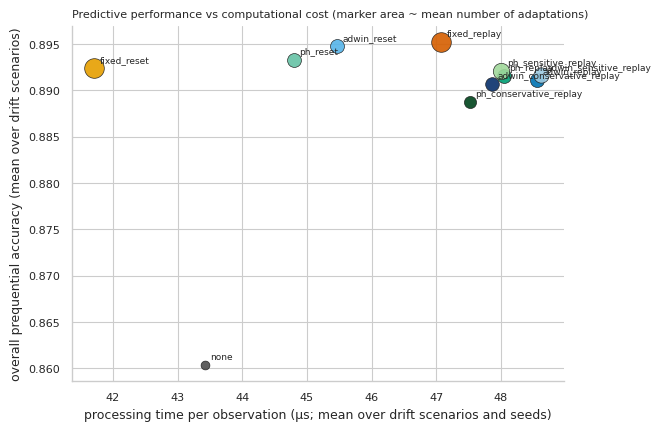

**Observed pattern (auto-generated from the executed results):** over concept-drift scenarios the highest mean overall accuracy is fixed_replay (0.895) and the lowest none (0.860); processing time per observation ranges from 41.7 µs (fixed_reset) to 48.6 µs (adwin_sensitive_replay).

In [28]:
fig = viz.fig_performance_vs_cost(res, cfg); viz.save_figure(fig, "fig13_performance_vs_cost", ROOT); plt.show()
specs_ = make_scenario_specs(cfg.stream)
dsub = res.runs[res.runs.scenario.map(lambda s: specs_[s].has_concept_drift)]
pc = dsub.groupby("policy").agg(acc=("overall_acc", "mean"), us=("us_per_obs", "mean"), ad=("n_adaptations", "mean"))
observed(f"over concept-drift scenarios the highest mean overall accuracy is {pc.acc.idxmax()} ({pc.acc.max():.3f}) and the lowest {pc.acc.idxmin()} ({pc.acc.min():.3f}); "
         f"processing time per observation ranges from {pc.us.min():.1f} µs ({pc.us.idxmin()}) to {pc.us.max():.1f} µs ({pc.us.idxmax()}).")

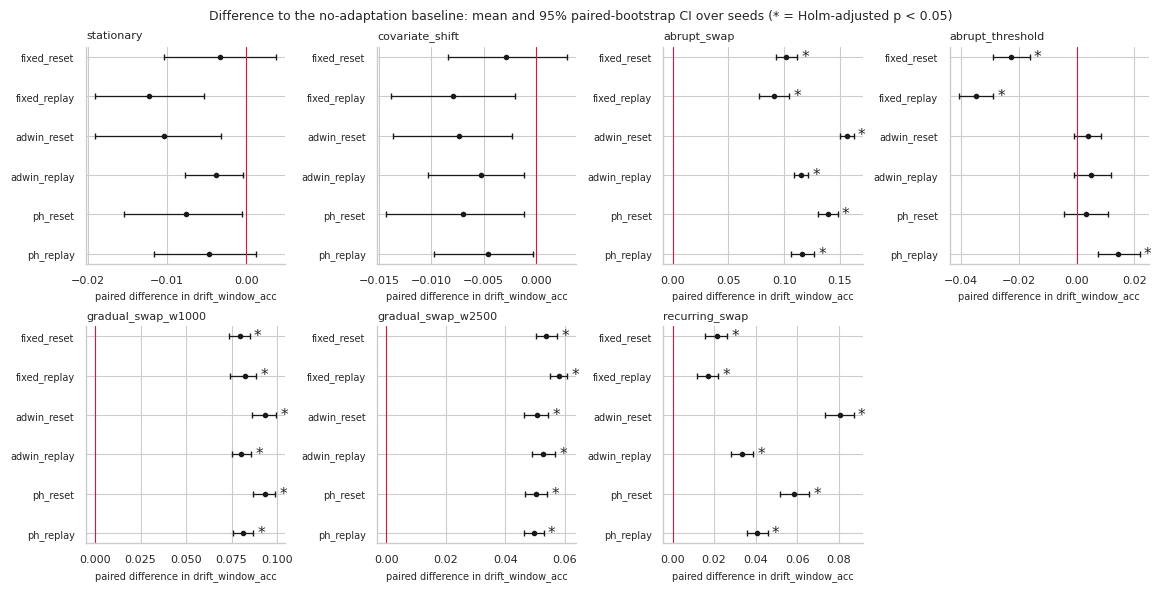

**Observed pattern (auto-generated from the executed results):** 27 of 42 policy-vs-none comparisons on drift-window accuracy are Holm-significant; CI widths range from 0.006 (gradual_swap_w2500/fixed_replay) to 0.027 (abrupt_swap/fixed_replay).

In [29]:
fig = viz.fig_uncertainty(st, "drift_window_acc"); viz.save_figure(fig, "fig14_statistical_uncertainty", ROOT); plt.show()
h2 = st[(st.hypothesis == "H2") & (st.metric == "drift_window_acc")]
widest = h2.assign(w=h2.ci_high - h2.ci_low).sort_values("w").iloc[-1]; narrow = h2.assign(w=h2.ci_high - h2.ci_low).sort_values("w").iloc[0]
observed(f"{int(h2.significant_holm.sum())} of {len(h2)} policy-vs-none comparisons on drift-window accuracy are Holm-significant; CI widths range from {narrow.w:.3f} ({narrow.scenario}/{narrow.condition}) to {widest.w:.3f} ({widest.scenario}/{widest.condition}).")

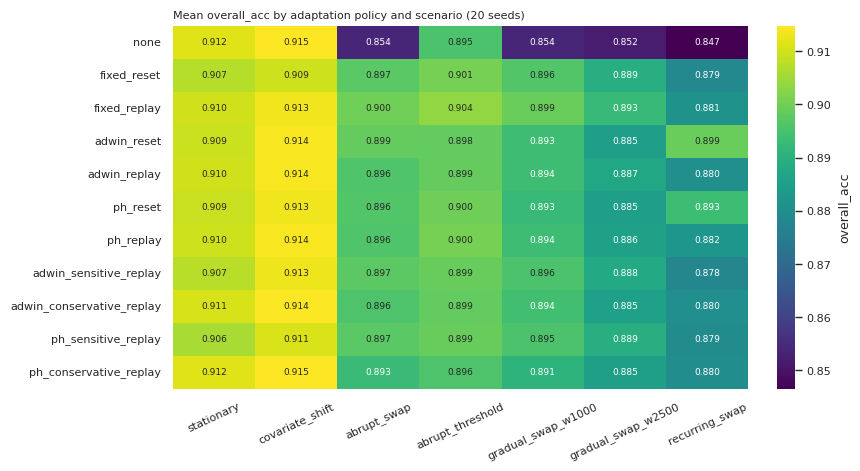

**Observed pattern (auto-generated from the executed results):** best policy per scenario by mean overall accuracy: abrupt_swap: fixed_replay (0.900); abrupt_threshold: fixed_replay (0.904); covariate_shift: none (0.915); gradual_swap_w1000: fixed_replay (0.899); gradual_swap_w2500: fixed_replay (0.893); recurring_swap: adwin_reset (0.899); stationary: none (0.912).

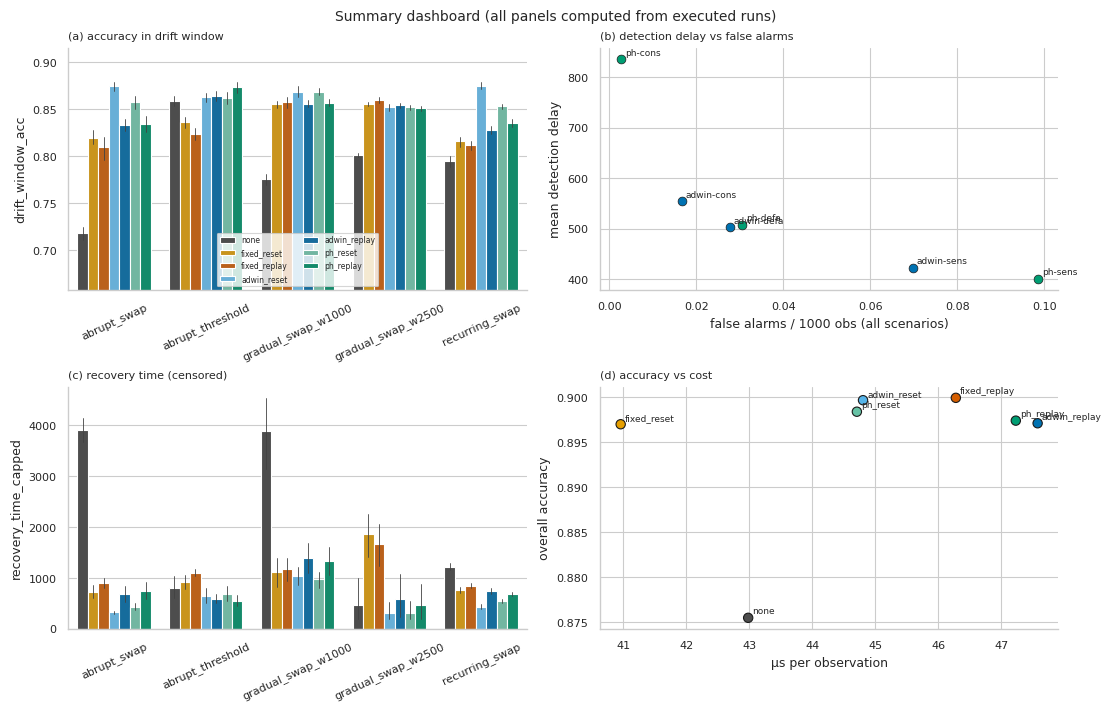

In [30]:
fig = viz.fig_heatmap(res, cfg, "overall_acc"); viz.save_figure(fig, "fig15_heatmap_overall_accuracy", ROOT); plt.show()
hm = res.runs.pivot_table(index="policy", columns="scenario", values="overall_acc", aggfunc="mean")
best = hm.idxmax(); observed("best policy per scenario by mean overall accuracy: " + "; ".join(f"{c}: {best[c]} ({hm[c].max():.3f})" for c in hm.columns) + ".")
fig = viz.fig_dashboard(res, cfg, tables); viz.save_figure(fig, "fig17_summary_dashboard", ROOT); plt.show()

In [31]:
# Figure 16 (real-world stream) is produced in Section 17 only if Elec2 is available.  Inventory of generated figure files:
inv = pd.DataFrame([{"file": p.name, "size_kB": round(p.stat().st_size / 1024, 1)} for p in sorted((ROOT / "figures").glob("fig*.png"))])
display(inv)
required_figs = ["fig01", "fig02", "fig03", "fig04", "fig05", "fig06", "fig07", "fig08", "fig09", "fig10", "fig11", "fig12", "fig13", "fig14", "fig15", "fig16", "fig17"]
missing_figs = [f for f in required_figs if not any(p.name.startswith(f) for p in (ROOT / "figures").glob("*.png"))]
print("required figures not generated:", missing_figs)

,file,size_kB
0,fig01_stream_overview.png,416.9
1,fig02_distributions_before_after.png,259.8
2,fig03_stationary_baseline.png,141.3
3,fig04_accuracy_with_drift.png,258.8
4,fig05_rolling_error_with_drift.png,415.1
5,fig06_adwin_timeline.png,277.2
6,fig07_pagehinkley_timeline.png,268.5
7,fig08_detector_comparison.png,170.5
8,fig09_detection_delay.png,179.2
9,fig10_false_alarms.png,199.9


required figures not generated: ['fig16']


---
## Section 16 — Results tables

All tables are exported to `results/tables/*.csv` (done in Section 10 via `save_tables`). Each table contains its grouping variables and `n_runs` (sample size per cell); parameters of the runs are in `results/raw/<tag>_runs.csv`. Tables report several metrics deliberately: **no single metric ranks the methods** — accuracy, recovery, false alarms, delay and cost pull in different directions.

In [32]:
exp = pd.DataFrame([{"table": p.name, "rows": len(pd.read_csv(p)), "columns": pd.read_csv(p, nrows=1).shape[1]} for p in sorted((ROOT / "results" / "tables").glob("*.csv"))])
display(exp)
display(tables["overall_model_performance"].round(3).head(14))
display(tables["results_by_drift_type"].round(3).head(12))

,table,rows,columns
0,adaptation_performance.csv,49,13
1,computational_cost.csv,77,14
2,detection_delay.csv,30,10
3,detector_performance.csv,42,13
4,false_alarms_and_missed.csv,42,13
5,friedman_omnibus.csv,14,6
6,h1_degradation.csv,7,20
7,model_comparison.csv,8,8
8,overall_model_performance.csv,49,13
9,recovery_sensitivity.csv,60,6


,scenario,policy,overall_acc_mean,overall_acc_sd,overall_err_mean,overall_err_sd,precision_mean,precision_sd,recall_mean,recall_sd,f1_mean,f1_sd,n_runs
0,stationary,none,0.912,0.005,0.088,0.005,0.916,0.007,0.954,0.004,0.935,0.004,20
1,stationary,fixed_reset,0.907,0.003,0.093,0.003,0.899,0.004,0.969,0.003,0.933,0.002,20
2,stationary,fixed_replay,0.910,0.003,0.090,0.003,0.903,0.004,0.969,0.004,0.934,0.002,20
3,stationary,adwin_reset,0.909,0.006,0.091,0.006,0.912,0.009,0.955,0.005,0.933,0.004,20
4,stationary,adwin_replay,0.910,0.006,0.090,0.006,0.913,0.008,0.955,0.004,0.933,0.004,20
5,stationary,ph_reset,0.909,0.007,0.091,0.007,0.912,0.010,0.955,0.004,0.933,0.005,20
6,stationary,ph_replay,0.910,0.006,0.090,0.006,0.913,0.008,0.954,0.004,0.933,0.005,20
7,covariate_shift,none,0.915,0.004,0.085,0.004,0.921,0.005,0.966,0.003,0.943,0.003,20
8,covariate_shift,fixed_reset,0.909,0.003,0.091,0.003,0.906,0.004,0.976,0.003,0.940,0.002,20
9,covariate_shift,fixed_replay,0.913,0.003,0.087,0.003,0.911,0.005,0.976,0.003,0.942,0.002,20


,scenario_kind,policy,overall_acc_mean,overall_acc_sd,drift_window_acc_mean,drift_window_acc_sd,recovery_time_capped_mean,recovery_time_capped_sd,n_runs
0,stationary,none,0.912,0.005,0.915,0.013,204.60,25.044,20
1,stationary,fixed_reset,0.907,0.003,0.912,0.013,243.00,131.256,20
2,stationary,fixed_replay,0.910,0.003,0.903,0.013,264.70,213.641,20
3,stationary,adwin_reset,0.909,0.006,0.905,0.020,277.20,171.050,20
4,stationary,adwin_replay,0.910,0.006,0.911,0.013,204.60,25.044,20
5,stationary,ph_reset,0.909,0.007,0.907,0.020,288.70,208.548,20
6,stationary,ph_replay,0.910,0.006,0.910,0.017,229.55,96.016,20
7,covariate,none,0.915,0.004,0.920,0.008,199.00,0.000,20
8,covariate,fixed_reset,0.909,0.003,0.917,0.012,199.00,0.000,20
9,covariate,fixed_replay,0.913,0.003,0.912,0.012,199.00,0.000,20


---
## Section 17 — Real-world validation (Elec2)

**Protocol (executed only when the dataset is available).** The same Hoeffding tree and the policies `none`, `fixed_replay`, `adwin_replay`, `ph_replay` (default settings) are run once over the chronological stream (the learner and detectors are deterministic, so there is no seed to replicate; results are descriptive and carry **no** significance claims). Because **no ground-truth drift timestamps exist**, no detection delay is computed: we report rolling accuracy, overall accuracy, alarm positions and adaptation counts only, and discuss seasonality, label timing and confounding in Section 19.

In [33]:
REALWORLD_EXECUTED = False
if ELEC2_AVAILABLE:
    recs, y_el = elec2_to_stream(elec_df)
    logs_rw = run_realworld(recs, y_el, cfg)
    rw = pd.DataFrame([{"policy": k, "n": v.n_obs, "overall_acc": 1 - v.errors.mean(), "alarms": len(v.alarms), "adaptations": len(v.adaptations),
                        "us_per_obs": 1e6 * v.timing["total_s"] / v.n_obs} for k, v in logs_rw.items()])
    display(rw.round(4)); rw.to_csv(ROOT / "results" / "tables" / "realworld_elec2.csv", index=False)
    fig = viz.fig_realworld(logs_rw); viz.save_figure(fig, "fig16_realworld_elec2", ROOT); plt.show()
    REALWORLD_EXECUTED = True
else:
    msg = ("Real-world validation NOT executed: Elec2 could not be loaded in this environment (documented source unreachable; no local copy in data/raw/). "
           "The synthetic study is the completed core experiment. To run Stage B, follow the alternative workflow printed in Section 8 and re-execute the notebook.")
    (ROOT / "results" / "logs" / "realworld_status.txt").write_text(msg + "\n\nLoader message:\n" + (ELEC2_ERROR or ""))
    display(Markdown("> **" + msg + "**\n>\n> Consequently Figure 16 and any statement about transfer of the synthetic findings to a real-world stream are **not** produced."))

> **Real-world validation NOT executed: Elec2 could not be loaded in this environment (documented source unreachable; no local copy in data/raw/). The synthetic study is the completed core experiment. To run Stage B, follow the alternative workflow printed in Section 8 and re-execute the notebook.**
>
> Consequently Figure 16 and any statement about transfer of the synthetic findings to a real-world stream are **not** produced.

---
## Section 18 — Discussion

Each research question is answered from the executed results. The text blocks below are **generated by code from the result tables** (no pre-written conclusions); the framing notes distinguish three levels of claim:

* **Observation** — what the data show in these runs (means, rates, counts).
* **Statistical evidence** — paired comparisons over independent seeds with Holm correction (Section 14).
* **Causal interpretation** — *why* it happened. The experiments are controlled (the stream, learner and policy settings are manipulated), so differences between policies on the same stream are attributable to the policies **under these settings**; explanations of mechanism (e.g. "the reset discarded useful structure") are hypotheses unless a dedicated experiment isolates them. No method is claimed to be universally superior.

### RQ1 — How do abrupt and gradual drifts affect performance and detection delay?

In [34]:
display(Markdown(rq1_text(res, tables, cfg)))

**Observation: degradation of the non-adapting model (H1).** Paired per-seed drop = pre-drift accuracy minus accuracy in the drift window (n = 20 runs per scenario):
- stationary (stationary): raw mean accuracy drop -0.008 (95% bootstrap CI [-0.014, -0.002], Holm p=0.0152, n=20).
- covariate_shift (covariate): raw mean accuracy drop -0.013 (95% bootstrap CI [-0.019, -0.007], Holm p=0.0044, n=20); relative to the stationary stream evaluated on the same windows (control drop -0.008) the excess drop is -0.005 (CI [-0.009, +0.000], d_z=-0.43, Holm p=0.0543).
- abrupt_swap (abrupt): raw mean accuracy drop +0.189 (95% bootstrap CI [+0.179, +0.198], Holm p=0.000353, n=20); relative to the stationary stream evaluated on the same windows (control drop -0.008) the excess drop is +0.197 (CI [+0.187, +0.206], d_z=8.75, Holm p=0.000442).
- abrupt_threshold (abrupt): raw mean accuracy drop +0.048 (95% bootstrap CI [+0.041, +0.056], Holm p=0.000353, n=20); relative to the stationary stream evaluated on the same windows (control drop -0.008) the excess drop is +0.056 (CI [+0.050, +0.063], d_z=3.71, Holm p=0.000442).
- gradual_swap_w1000 (gradual): raw mean accuracy drop +0.131 (95% bootstrap CI [+0.120, +0.142], Holm p=1.34e-05, n=20); relative to the stationary stream evaluated on the same windows (control drop -0.010) the excess drop is +0.141 (CI [+0.134, +0.148], d_z=8.73, Holm p=0.000442).
- gradual_swap_w2500 (gradual): raw mean accuracy drop +0.094 (95% bootstrap CI [+0.086, +0.102], Holm p=1.34e-05, n=20); relative to the stationary stream evaluated on the same windows (control drop -0.019) the excess drop is +0.113 (CI [+0.109, +0.117], d_z=11.40, Holm p=0.000442).
- recurring_swap (recurring): raw mean accuracy drop +0.075 (95% bootstrap CI [+0.068, +0.081], Holm p=1.34e-05, n=20); relative to the stationary stream evaluated on the same windows (control drop +0.005) the excess drop is +0.070 (CI [+0.064, +0.076], d_z=5.10, Holm p=1.14e-05).

**Detection under default settings** (monitor-only; delay in observations after drift onset, undefined for missed events):
- abrupt_swap / ADWIN: detection rate 1.00, mean delay from onset 108 (from transition end 108), mean false alarms per run 0.25.
- abrupt_swap / PH: detection rate 1.00, mean delay from onset 184 (from transition end 184), mean false alarms per run 0.25.
- abrupt_threshold / ADWIN: detection rate 0.25, mean delay from onset 567 (from transition end 567), mean false alarms per run 0.35.
- abrupt_threshold / PH: detection rate 0.50, mean delay from onset 488 (from transition end 488), mean false alarms per run 0.55.
- gradual_swap_w1000 / ADWIN: detection rate 0.95, mean delay from onset 624 (from transition end -376), mean false alarms per run 0.25.
- gradual_swap_w1000 / PH: detection rate 1.00, mean delay from onset 612 (from transition end -388), mean false alarms per run 0.25.
- gradual_swap_w2500 / ADWIN: detection rate 1.00, mean delay from onset 1118 (from transition end -1382), mean false alarms per run 0.25.
- gradual_swap_w2500 / PH: detection rate 1.00, mean delay from onset 931 (from transition end -1569), mean false alarms per run 0.20.
- recurring_swap / ADWIN: detection rate 0.62, mean delay from onset 153 (from transition end 153), mean false alarms per run 0.05.
- recurring_swap / PH: detection rate 0.62, mean delay from onset 314 (from transition end 314), mean false alarms per run 0.05.

Averaged over detectors, mean delay from onset is 337 for abrupt and 821 for gradual scenarios; part of the gradual figure reflects that the new concept is only partially present early in the transition, so delay measured from onset is not directly comparable with abrupt delay.

**Caution on delays:** delay exists only for detected events, so it is conditional on detection (survivorship); settings with low detection rates (abrupt_threshold/ADWIN 0.25, abrupt_threshold/PH 0.50, recurring_swap/ADWIN 0.62, recurring_swap/PH 0.62) are summarised by few events and should be read together with the detection rate.
The negative raw 'drop' on control streams means accuracy *rose* after the midpoint/shift because the learner keeps improving; the excess drop relative to the stationary control (above) is the more appropriate estimate of drift-attributable degradation.

### RQ2 — Drift-triggered vs fixed-window vs no retraining: performance and recovery

In [35]:
display(Markdown(rq2_text(res, tables, cfg)))

- abrupt_swap, mean drift-window accuracy (higher is better): best -> adwin_reset (0.874), ph_reset (0.857), ph_replay (0.834); worst: none (0.718).
  Significantly better than no adaptation (Holm p<0.05): fixed_reset, fixed_replay, adwin_reset, adwin_replay, ph_reset, ph_replay; significantly worse: none.
  abrupt_swap, mean censored recovery time (lower is better): best -> adwin_reset (327), ph_reset (437), adwin_replay (678); worst: none (3896).
- abrupt_threshold, mean drift-window accuracy (higher is better): best -> ph_replay (0.873), adwin_replay (0.864), adwin_reset (0.862); worst: fixed_replay (0.824).
  Significantly better than no adaptation (Holm p<0.05): ph_replay; significantly worse: fixed_reset, fixed_replay.
  abrupt_threshold, mean censored recovery time (lower is better): best -> ph_replay (550), adwin_replay (591), adwin_reset (639); worst: fixed_replay (1104).
- gradual_swap_w1000, mean drift-window accuracy (higher is better): best -> adwin_reset (0.869), ph_reset (0.869), fixed_replay (0.858); worst: none (0.775).
  Significantly better than no adaptation (Holm p<0.05): fixed_reset, fixed_replay, adwin_reset, adwin_replay, ph_reset, ph_replay; significantly worse: none.
  gradual_swap_w1000, mean censored recovery time (lower is better): best -> ph_reset (972), adwin_reset (1038), fixed_reset (1114); worst: none (3882).
- gradual_swap_w2500, mean drift-window accuracy (higher is better): best -> fixed_replay (0.859), fixed_reset (0.855), adwin_replay (0.854); worst: none (0.801).
  Significantly better than no adaptation (Holm p<0.05): fixed_reset, fixed_replay, adwin_reset, adwin_replay, ph_reset, ph_replay; significantly worse: none.
  gradual_swap_w2500, mean censored recovery time (lower is better): best -> adwin_reset (319), ph_reset (319), none (470); worst: fixed_reset (1853).
- recurring_swap, mean drift-window accuracy (higher is better): best -> adwin_reset (0.875), ph_reset (0.853), ph_replay (0.835); worst: none (0.795).
  Significantly better than no adaptation (Holm p<0.05): fixed_reset, fixed_replay, adwin_reset, adwin_replay, ph_reset, ph_replay; significantly worse: none.
  recurring_swap, mean censored recovery time (lower is better): best -> adwin_reset (433), ph_reset (554), ph_replay (681); worst: none (1220).

**Cost of adapting when nothing changes (stationary stream, overall accuracy difference to no adaptation):** fixed_reset -0.0043 (Holm p=0.00405); fixed_replay -0.0016 (Holm p=0.625); adwin_reset -0.0022 (Holm p=0.5); adwin_replay -0.0017 (Holm p=0.5); ph_reset -0.0026 (Holm p=0.344); ph_replay -0.0019 (Holm p=0.344).

**Reset vs replay (drift-window accuracy, same trigger):** reset has the higher mean in 10 of 15 (scenario, trigger) pairs; mean difference (reset - replay) by trigger: adwin +0.020; ph +0.008; fixed +0.004. A replay window can still contain mostly old-concept observations when an alarm is late, which is one candidate explanation (not tested separately here).

Across the 20 (drift scenario x drift-triggered policy) comparisons on drift-window accuracy, 17 were significantly better than no adaptation after Holm correction and 0 significantly worse.

### RQ3 — Trade-offs between performance, delay, false alarms and overhead

In [36]:
display(Markdown(rq3_text(res, tables, cfg)))

- **ADWIN** (pooled over scenarios; sensitive -> conservative): mean delay 422 / 503 / 554; false alarms per 1000 obs 0.070 / 0.028 / 0.017; detection rate 0.84 / 0.76 / 0.76; detector update cost (µs) 0.7 / 0.8 / 0.8. Delay non-decreasing with conservativeness: True; false-alarm rate non-increasing: True.
- **PH** (pooled over scenarios; sensitive -> conservative): mean delay 400 / 508 / 836; false alarms per 1000 obs 0.099 / 0.030 / 0.003; detection rate 0.89 / 0.82 / 0.67; detector update cost (µs) 0.8 / 0.8 / 0.8. Delay non-decreasing with conservativeness: True; false-alarm rate non-increasing: True.
- Sensitive vs conservative, `detection_delay`: 8 of 9 scenario/detector comparisons significant after Holm; mean paired difference ranges -627 to -54.4.
- Sensitive vs conservative, `false_alarms_per_1000`: 11 of 14 scenario/detector comparisons significant after Holm; mean paired difference ranges 0.0143 to 0.138.
- In-loop adaptation counts (sensitive vs conservative replay policies): 15 of 28 comparisons significant (Holm); mean extra adaptations per run range 0.05 to 3.00.
- *Note:* pooled delays are computed over *detected* events only; settings that detect fewer events (see detection rates) are summarised on different, typically easier, subsets. The paired tests below use only seeds where both settings detected.

**Computational overhead per observation** (mean over scenarios; relative to no adaptation = 43.0 µs): none 43.0 µs; fixed_reset 41.0 µs; fixed_replay 46.3 µs; adwin_reset 44.8 µs; adwin_replay 47.6 µs; ph_reset 44.7 µs; ph_replay 47.2 µs; adwin_sensitive_replay 47.5 µs; adwin_conservative_replay 46.9 µs; ph_sensitive_replay 47.3 µs; ph_conservative_replay 46.7 µs. Run-to-run SD of the per-observation time is about 5.0 µs, and the time may also depend on tree size (a hypothesis not tested here), so differences of a few µs between policies cannot be attributed to detector overhead; the measured detector update itself costs at most 3.8 µs per observation.

### Transfer to the real-world stream, and why hypotheses may not be supported

In [37]:
if REALWORLD_EXECUTED:
    display(Markdown("Real-world results are in Section 17 (descriptive only: single deterministic pass, no ground-truth drift points). Whether they resemble the synthetic ordering of policies must be judged from `results/tables/realworld_elec2.csv`; no significance is claimed."))
else:
    display(Markdown("**Generalisation to a real-world stream could not be assessed in this execution because Elec2 was unavailable (Section 8).** All conclusions are limited to the synthetic streams."))
display(Markdown("**Reasons a hypothesis may fail in this design (to be weighed against the results above):** (i) the Hoeffding tree keeps learning after a drift, so for mild or gradual changes the no-adaptation baseline may already recover; (ii) late detection means the replay window still contains old-concept data; (iii) resets discard useful structure and false alarms make this costly; (iv) ADWIN and Page-Hinkley parameters are not equivalent, so 'sensitive' levels are not matched in power; (v) with a finite number of seeds, small effects cannot be distinguished from noise."))

**Generalisation to a real-world stream could not be assessed in this execution because Elec2 was unavailable (Section 8).** All conclusions are limited to the synthetic streams.

**Reasons a hypothesis may fail in this design (to be weighed against the results above):** (i) the Hoeffding tree keeps learning after a drift, so for mild or gradual changes the no-adaptation baseline may already recover; (ii) late detection means the replay window still contains old-concept data; (iii) resets discard useful structure and false alarms make this costly; (iv) ADWIN and Page-Hinkley parameters are not equivalent, so 'sensitive' levels are not matched in power; (v) with a finite number of seeds, small effects cannot be distinguished from noise.

---
## Section 19 — Threats to validity and limitations

* **Synthetic-to-real generalisation.** SEA-style streams have uniform features, a simple linear rule and a known, clean change; real streams have correlated features, seasonality, delayed or noisy labels and no known change points. Findings are claims about these generators.
* **Dependence on selected datasets.** One synthetic family (SEA with a swap and a threshold change) and, if available, one real stream (Elec2, a single market in one period).
* **Elec2 specifics.** The source file is pre-normalised over the whole period (mild look-ahead outside our control); its time information is a normalised date, not calendar timestamps, limiting seasonal analysis; labels (price up/down relative to a moving average) are available with essentially no delay, which is not guaranteed in deployments.
* **Detector parameter sensitivity.** Three a-priori levels per detector; ADWIN `delta` and PH `threshold` are not equivalent, other PH parameters were fixed, and other detectors (DDM, EDDM, KSWIN, …) are not evaluated.
* **Model choice.** One main learner (Hoeffding tree) and a two-scenario Naive Bayes sub-experiment; conclusions may differ for other learners (including learners with built-in drift handling).
* **Random-seed variability.** 20 seeds; paired tests have limited power for small effects, and bootstrap intervals are approximate. Models and detectors are deterministic, so seed variability reflects the data stream only.
* **Computational-measurement noise.** Wall-clock timings come from one shared CPU core; memory is measured in a separate, small pass with `tracemalloc` (Python-level allocations only).
* **Definition of drift and delay.** Delay depends on the matching window (1000 observations of tolerance), on measuring from the onset (for gradual drift the new concept is only partly present early), and alarms inside a window after the first are ignored.
* **Label-availability assumption.** The protocol assumes the true label arrives immediately after prediction. Delayed or partial labels would delay both detection and adaptation.
* **Fixed-window retraining.** One window size ($W=2000$) and one replay size ($R=500$) were used; the fixed policy rebuilds regardless of drift and its cost/benefit depends strongly on $W$ and on how often drift occurs.
* **Notebook vs production.** No latency budgets, concurrency, data validation, monitoring infrastructure or human review; nothing here was deployed or validated in production.
* **Recovery definition.** Thresholds (95 %, 200-observation hold) are conventions; Section 13 shows sensitivity but not invariance.

**Additional experiments that would strengthen the findings:** more learners and detectors; several window sizes $W$ and replay sizes $R$; delayed labels; recurring and incremental drift at different frequencies; real streams with externally documented change events; larger numbers of seeds for small effects.

---
## Section 20 — Conclusion and future work

The conclusion below is produced from the executed results (Sections 10–14). It reports evidence relevant to the hypotheses without introducing new results and with the limitations of Section 19.

In [38]:
display(Markdown(conclusion_text(res, tables, cfg)))
if not REALWORLD_EXECUTED:
    display(Markdown("- **Real-world validation:** not executed (Elec2 unreachable here); no claim is made about transfer to real data."))

- **H1** (degradation): relative to the stationary stream evaluated on identical windows, the no-adaptation model lost accuracy in 5 of 5 concept-drift scenarios (Holm-significant); excess drops range +0.056 to +0.197. Control streams (raw drops; negative = accuracy rose): stationary -0.008; covariate_shift -0.013 (excess vs stationary -0.005, Holm p=0.0543).
- **H2** `adwin_replay`: improves drift-window accuracy over no adaptation in 4 of 5 drift scenarios (Holm), worse in 0; mean paired difference +0.057.
- **H2** `adwin_reset`: improves drift-window accuracy over no adaptation in 4 of 5 drift scenarios (Holm), worse in 0; mean paired difference +0.077.
- **H2** `fixed_replay`: improves drift-window accuracy over no adaptation in 4 of 5 drift scenarios (Holm), worse in 1; mean paired difference +0.043.
- **H2** `fixed_reset`: improves drift-window accuracy over no adaptation in 4 of 5 drift scenarios (Holm), worse in 1; mean paired difference +0.047.
- **H2** `ph_replay`: improves drift-window accuracy over no adaptation in 5 of 5 drift scenarios (Holm), worse in 0; mean paired difference +0.060.
- **H2** `ph_reset`: improves drift-window accuracy over no adaptation in 4 of 5 drift scenarios (Holm), worse in 0; mean paired difference +0.069.
- **H3**: see the sensitivity statements under RQ3, which report whether delay fell and false alarms rose with sensitivity in these data (paired, Holm-corrected).
- Evidence base: 20 independent seeds per cell, 1540 prequential runs, 0 failed runs.

- **Real-world validation:** not executed (Elec2 unreachable here); no claim is made about transfer to real data.

**Contribution statement (to be adopted only if consistent with the evidence above).** A reproducible, laptop-scale empirical comparison of ADWIN and Page-Hinkley detection and of reset/replay adaptation policies under explicit, separately controlled change mechanisms (concept change with and without class-prevalence change, and a covariate-shift control), with paired multi-seed statistics. It is *not* a new algorithm and makes no claim to be the first such comparison.

**Future work.** Recurring drift at several frequencies; incremental drift; unsupervised (label-free) drift detection; delayed and partially missing labels; ensemble adaptation (e.g. replacing only part of the model); additional real streams with documented events; tuning protocols with proper nested evaluation; online monitoring in deployed systems (not performed here).

---
## Section 21 — References (IEEE style; verified sources only)

[1] J. Gama, I. Žliobaitė, A. Bifet, M. Pechenizkiy, and A. Bouchachia, "A survey on concept drift adaptation," *ACM Comput. Surv.*, vol. 46, no. 4, Art. no. 44, 2014, doi: 10.1145/2523813.

[2] J. Lu, A. Liu, F. Dong, F. Gu, J. Gama, and G. Zhang, "Learning under concept drift: A review," *IEEE Trans. Knowl. Data Eng.*, vol. 31, no. 12, pp. 2346–2363, 2019, doi: 10.1109/TKDE.2018.2876857.

[3] A. Bifet and R. Gavaldà, "Learning from time-changing data with adaptive windowing," in *Proc. 7th SIAM Int. Conf. Data Mining (SDM)*, 2007, pp. 443–448, doi: 10.1137/1.9781611972771.42.

[4] E. S. Page, "Continuous inspection schemes," *Biometrika*, vol. 41, no. 1–2, pp. 100–115, 1954, doi: 10.1093/biomet/41.1-2.100.

[5] D. V. Hinkley, "Inference about the change-point from cumulative sum tests," *Biometrika*, vol. 58, no. 3, pp. 509–523, 1971, doi: 10.1093/biomet/58.3.509.

[6] J. Gama, R. Sebastião, and P. P. Rodrigues, "On evaluating stream learning algorithms," *Mach. Learn.*, vol. 90, no. 3, pp. 317–346, 2013, doi: 10.1007/s10994-012-5320-9.

[7] P. M. Gonçalves Jr., S. G. T. de Carvalho Santos, R. S. M. Barros, and D. C. L. Vieira, "A comparative study on concept drift detectors," *Expert Syst. Appl.*, 2014, doi: 10.1016/j.eswa.2014.07.019.

[8] R. S. M. Barros and S. G. T. Santos, "A large-scale comparison of concept drift detectors," *Inf. Sci.*, vols. 451–452, pp. 348–370, 2018, doi: 10.1016/j.ins.2018.04.014.

[9] W. N. Street and Y. Kim, "A streaming ensemble algorithm (SEA) for large-scale classification," in *Proc. 7th ACM SIGKDD Int. Conf. Knowl. Discov. Data Mining (KDD '01)*, 2001, pp. 377–382, doi: 10.1145/502512.502568.

[10] P. Domingos and G. Hulten, "Mining high-speed data streams," in *Proc. 6th ACM SIGKDD Int. Conf. Knowl. Discov. Data Mining (KDD '00)*, 2000, p. 71 ff., doi: 10.1145/347090.347107.

[11] J. Montiel *et al.*, "River: Machine learning for streaming data in Python," *J. Mach. Learn. Res.*, vol. 22, no. 110, pp. 1–8, 2021. [Online]. Available: https://jmlr.org/papers/v22/20-1380.html

[12] S. Holm, "A simple sequentially rejective multiple test procedure," *Scand. J. Stat.*, vol. 6, no. 2, pp. 65–70, 1979.

[13] "SPLICE-2 comparative evaluation: Electricity pricing," as cited in the River documentation for `datasets.Elec2`. [Online]. Available: http://citeseerx.ist.psu.edu/viewdoc/summary?doi=10.1.1.12.9405 *(author and venue not verified in this project)*.

[14] River documentation, "Elec2." [Online]. Available: https://riverml.xyz/dev/api/datasets/Elec2/

**In-text mapping:** detectors [3]–[5]; evaluation [6]; detector benchmarking [7], [8]; reviews [1], [2]; SEA generator [9]; Hoeffding tree [10]; software [11]; Holm correction [12]; Elec2 [13], [14]. Unverified candidates are listed in the Section 3 checklist and are intentionally absent from this list. The same entries are in `reports/references.bib`.

---
## Section 22 — Final reproducibility checklist and summary

All checks below are executed; a failed check raises an assertion so that a broken run cannot be mistaken for a successful one. The only non-assertion item is the real-world stream, whose availability is reported as a status.

In [39]:
rep = []
def rec(name, ok, detail=""):
    rep.append({"check": name, "passed": bool(ok), "detail": detail})

n_expected_runs = len(cfg.run.scenarios) * cfg.run.n_seeds * len({**build_policy_specs(cfg), **build_sensitivity_policy_specs(cfg)})
rec("imports / library versions recorded", env["import_ok"].all(), f"{len(env)} packages")
rec("API compatibility checks", compat["passed"].all(), f"{len(compat)} checks")
rec("synthetic data available (generated)", GENERATOR_VALID, "generator validated against its configuration")
rec("Elec2 available", ELEC2_AVAILABLE, "STATUS ONLY (not an assertion): " + ("loaded" if ELEC2_AVAILABLE else "unreachable here; Stage B not executed"))
rec("deterministic reproduction (same seed -> same predictions)", DETERMINISM_OK)
rec("unit tests", TESTS_PASSED)
rec("experiment completion (expected number of runs, no failures)", len(res.runs) == n_expected_runs and len(res.failed) == 0, f"{len(res.runs)} of {n_expected_runs} runs; failed={len(res.failed)}")
rec("fair-comparison prefix check", FAIRNESS_OK); rec("adaptation events only at documented triggers", TRIGGERS_OK)

exp_files = [f"results/raw/{TAG}_runs.csv", f"results/raw/{TAG}_drift_events.csv", f"results/raw/{TAG}_monitor_runs.csv", f"results/raw/{TAG}_memory.csv",
             f"results/logs/{TAG}_event_log.csv", f"results/logs/{TAG}_prequential_errors.npz", f"results/logs/{TAG}_config.json", "results/logs/environment.txt"] + \
            [f"results/tables/{n}.csv" for n in tables] + ["results/tables/model_comparison.csv"]
miss = [f for f in exp_files if not (ROOT / f).exists() or (ROOT / f).stat().st_size == 0]
rec("expected output files exist and are non-empty", not miss, f"{len(exp_files)} files; missing={miss}")

bad_tab = []
for n, t in tables.items():
    num = t.select_dtypes(include=[np.number])
    if np.isinf(num.to_numpy(dtype=float)).any(): bad_tab.append(n + ":inf")
    if t.empty and n != "recovery_sensitivity": bad_tab.append(n + ":empty")
r_ = res.runs
rng_ok = r_[["overall_acc", "precision", "recall", "f1"]].dropna().apply(lambda c: c.between(0, 1)).all().all()
nan_core = r_[["overall_acc", "overall_err", "us_per_obs", "n_adaptations"]].isna().any().any()
rec("result tables valid (no inf/empty) and metrics in range", not bad_tab and rng_ok and not nan_core, str(bad_tab))
# delay may be NaN ONLY for missed events / scenarios without events
mm = res.monitor_runs
delay_ok = (mm[mm.n_events > 0].assign(bad=lambda d: d.detection_delay.isna() & (d.n_detected > 0)).bad.sum() == 0) and (mm[mm.n_events == 0].detection_delay.isna().all())
rec("missing detection delays occur only for missed events / no-event streams", delay_ok)

figs_ok, fig_detail = True, []
for f in required_figs:
    if f == "fig16" and not REALWORLD_EXECUTED: continue
    pngs = list((ROOT / "figures").glob(f + "*.png")); pdfs = list((ROOT / "figures").glob(f + "*.pdf"))
    if not pngs or not pdfs or min(p.stat().st_size for p in pngs) < 5_000: figs_ok = False; fig_detail.append(f)
rec("figure exports (PNG 300 DPI + PDF)" , figs_ok, f"problem figures: {fig_detail}")

# consistency of logged drift points and alarms
cfg_on = sorted({o for s in cfg.run.scenarios for o in specs[s].onsets})
ev_on = sorted(res.events.dropna(subset=["onset"])["onset"].unique())
lg = res.alarm_log
rec("logged drift points equal configured points", set(res.events[res.events.scenario.isin([s for s in cfg.run.scenarios if specs[s].has_concept_drift])]["onset"]) == set(cfg_on))
rec("alarm positions within stream and consistent with counts", lg["t"].between(0, cfg.stream.length - 1).all() and
    (lg[lg.policy.str.startswith("monitor:")].groupby(["scenario", "seed", "policy"]).size().sum() == int(mm["n_alarms"].sum())))
chk = pd.DataFrame(rep); display(chk)
assert chk[chk.check != "Elec2 available"]["passed"].all(), "reproducibility check failed"
print("ALL EXECUTABLE CHECKS PASSED" + ("" if ELEC2_AVAILABLE else " (Elec2 not available: Stage B not executed)"))

,check,passed,detail
0,imports / library versions recorded,True,13 packages
1,API compatibility checks,True,9 checks
2,synthetic data available (generated),True,generator validated against its configuration
3,Elec2 available,False,STATUS ONLY (not an assertion): unreachable he...
4,deterministic reproduction (same seed -> same ...,True,
5,unit tests,True,
6,experiment completion (expected number of runs...,True,1540 of 1540 runs; failed=0
7,fair-comparison prefix check,True,
8,adaptation events only at documented triggers,True,
9,expected output files exist and are non-empty,True,22 files; missing=[]


ALL EXECUTABLE CHECKS PASSED (Elec2 not available: Stage B not executed)


In [40]:
# ---- write the results summary (from executed results only) and the validation report ----
def md_table(df, digits=3):
    d = df.copy()
    for c in d.select_dtypes(include=[float]).columns: d[c] = d[c].round(digits)
    head = "| " + " | ".join(map(str, d.columns)) + " |\n|" + "|".join(["---"] * len(d.columns)) + "|\n"
    return head + "\n".join("| " + " | ".join(map(str, r)) + " |" for r in d.itertuples(index=False))

summary = [f"# Results summary (auto-generated by notebook execution, profile `{PROFILE}`)\n",
           f"Runs: {len(res.runs)}; seeds per cell: {res.runs.seed.nunique()}; stream length: {cfg.stream.length}; failed runs: {len(res.failed)}.\n",
           "All numbers below come from `results/tables/*.csv`. Real-world validation: " + ("executed" if REALWORLD_EXECUTED else "**not executed (Elec2 unavailable)**") + ".\n",
           "## H1 — degradation of the no-adaptation model\n", md_table(tables["h1_degradation"][["scenario", "reference_type", "n_runs", "mean_pre_acc", "mean_drift_window_acc", "mean_drop", "control_drop_same_windows", "did_mean", "did_ci_low", "did_ci_high", "did_p_holm"]]),
           "\n## RQ1\n", rq1_text(res, tables, cfg), "\n## RQ2\n", rq2_text(res, tables, cfg), "\n## RQ3\n", rq3_text(res, tables, cfg),
           "\n## Conclusions supported by the data\n", conclusion_text(res, tables, cfg), "\n## Limitations\nSee `reports/limitations.md`.\n"]
(ROOT / "reports" / "results_summary.md").write_text("\n".join(summary))
vr = ["# Validation report (auto-generated)\n", f"- Profile: `{PROFILE}`", f"- Python {PYTHON_VERSION}; River {md.version('river')}; NumPy {md.version('numpy')}; pandas {md.version('pandas')}; scikit-learn {md.version('scikit-learn')}",
      f"- Main study runtime: {RUNTIME_MAIN_S/60:.1f} min on {os.cpu_count()} CPU core(s)", f"- Elec2 available: {ELEC2_AVAILABLE}; real-world validation executed: {REALWORLD_EXECUTED}",
      "\n## Executed checks\n", md_table(chk)]
(ROOT / "reports" / "validation_report.md").write_text("\n".join(vr))
print("wrote reports/results_summary.md and reports/validation_report.md")

wrote reports/results_summary.md and reports/validation_report.md


In [41]:
# ---- final summary of completed experiments and exported artifacts ----
artifacts = sorted(p.relative_to(ROOT).as_posix() for d in ("results", "figures", "reports") for p in (ROOT / d).rglob("*") if p.is_file() and not p.name.startswith("."))
display(Markdown(f"### Summary of this execution\n"
    f"- **Profile:** `{PROFILE}` ({'FULL study' if PROFILE == 'full' else 'SMOKE check — do not report'})\n"
    f"- **Completed:** {len(res.runs)} prequential runs ({len(cfg.run.scenarios)} scenarios × {cfg.run.n_seeds} seeds × 11 policies), "
    f"{len(res.monitor_runs)} monitor-only detector evaluations, model-effect sub-experiment, memory pass, statistics for H1–H3.\n"
    f"- **Not completed:** " + ("none" if REALWORLD_EXECUTED else "Stage B real-world validation (Elec2 unreachable in this environment).") + "\n"
    f"- **Artifacts exported:** {len(artifacts)} files under `results/`, `figures/`, `reports/`."))
print("\n".join(artifacts[:80]) + ("\n..." if len(artifacts) > 80 else ""))

### Summary of this execution
- **Profile:** `full` (FULL study)
- **Completed:** 1540 prequential runs (7 scenarios × 20 seeds × 11 policies), 840 monitor-only detector evaluations, model-effect sub-experiment, memory pass, statistics for H1–H3.
- **Not completed:** Stage B real-world validation (Elec2 unreachable in this environment).
- **Artifacts exported:** 65 files under `results/`, `figures/`, `reports/`.

figures/README.md
figures/fig01_stream_overview.pdf
figures/fig01_stream_overview.png
figures/fig02_distributions_before_after.pdf
figures/fig02_distributions_before_after.png
figures/fig03_stationary_baseline.pdf
figures/fig03_stationary_baseline.png
figures/fig04_accuracy_with_drift.pdf
figures/fig04_accuracy_with_drift.png
figures/fig05_rolling_error_with_drift.pdf
figures/fig05_rolling_error_with_drift.png
figures/fig06_adwin_timeline.pdf
figures/fig06_adwin_timeline.png
figures/fig07_pagehinkley_timeline.pdf
figures/fig07_pagehinkley_timeline.png
figures/fig08_detector_comparison.pdf
figures/fig08_detector_comparison.png
figures/fig09_detection_delay.pdf
figures/fig09_detection_delay.png
figures/fig10_false_alarms.pdf
figures/fig10_false_alarms.png
figures/fig11_policy_curves.pdf
figures/fig11_policy_curves.png
figures/fig12_recovery_time.pdf
figures/fig12_recovery_time.png
figures/fig13_performance_vs_cost.pdf
figures/fig13_performance_vs_cost.png
figures/fig14_statistical_uncert